# FAMP: diagnosis-guided executable functional memory
## End-to-end continual learning, exact-byte accounting, and research decisions

**Fixed research objective:** replace some episodic replay with reusable *executable learned computations*, while retaining competitive old/new-task accuracy at lower total resource cost. This is not a gradient-projection notebook or a standalone causal-diagnosis study.

This notebook builds the system from scratch, compares eight controlled conditions, saves all checkpoints and decisions, and generates its interpretation from measured results. The accompanying MLSys manuscript intentionally has **empty result tables**: pilot outcomes never populate confirmatory tables automatically.

**Scope:** task identity is supplied at inference. Units are small learned feature networks, not hard-coded arithmetic functions and not certified symbolic abstractions. Temporary training workspace is distinguished from published persistent state. The included CPU run is a development experiment, not a GPU result or full CIFAR-100 confirmation.

## 1. Reproducibility and dependencies
Upload this notebook to Colab and run all cells. No token, paid API, previous ZIP, pretrained model, or Drive mount is required. Install only missing packages. The optional CIFAR runner downloads the official dataset and fails explicitly if unavailable. All measured numbers below are regenerated by this execution.

In [1]:
import importlib.util, subprocess, sys
packages={"torch":"torch", "numpy":"numpy", "pandas":"pandas", "scipy":"scipy", "sklearn":"scikit-learn", "matplotlib":"matplotlib", "tabulate":"tabulate"}
missing=[p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
from pathlib import Path
from IPython.display import display, Markdown, Image


## 2. What is stored—and what is not?
The published state contains (i) the mutable fallback network, (ii) each immutable unit exactly once, (iii) every task-specific head and route, (iv) small stored validation witnesses, (v) a bounded replay buffer for unresolved tasks, and (vi) canonical metadata.

A task follows `head(concatenate(unit_1(x), unit_2(x)))` after admission. Later tasks can refer to those same parameter objects. Admitted tasks drop ordinary replay records; unresolved tasks still use the mutable fallback plus replay. Candidate modules, Adam state, gradients, and current-task data occupy temporary workspace and are not hidden inside the persistent-byte claim. They remain real costs.

The following cells write fully visible source code rather than downloading an uninspectable engine.

## 3. Data, partitions, perturbations, and fixed configuration
Synthetic learners see raw inputs and task IDs, never primitive values. Train, selection, acceptance, and test are separately generated. Digits is five **task-aware binary** problems. CIFAR is ten **task-aware ten-way** problems, not 100-way class-incremental inference.

In [2]:
%%writefile famp_engine.py
"""FAMP v1.0: executable functional memory, not parameter-gradient memory.

Task-incremental classification with an explicitly supplied task ID. A mutable
fallback predictor is shared by all methods. FAMP may replace a task's replay
records with immutable learned feature units, a task head and bounded witnesses.
All commit-state tensors and canonical metadata are priced in bytes. Scratch
training, selection and certification are included in time, but are not claimed
as persistent memory. This research prototype is NOT a verified abstraction or
an accuracy/memory improvement. See generated report for actual measurements.
"""
from __future__ import annotations
import argparse, copy, hashlib, json, math, os, platform, random, struct, sys, time, zipfile
from dataclasses import dataclass, asdict, replace
from pathlib import Path
from typing import Any
import numpy as np
import pandas as pd
import scipy
from scipy.stats import beta, t as student_t
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

PROTOCOL='famp-executable-memory-1.1.1'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(1)

@dataclass
class Config:
    profile: str='pilot'
    seeds: tuple=(811, 823, 839)
    families: tuple=('arithmetic','nonlinear','digits')
    methods: tuple=('er_fp32','er_comp','derpp','independent','famp','no_cf','ungated','shuffled_cf')
    budgets: tuple=(24576,49152)
    digit_budgets: tuple=(49152,)
    tasks: int=9
    train_n: int=768
    select_n: int=128
    accept_n: int=256
    test_n: int=768
    teacher_steps: int=120
    unit_steps: int=120
    head_steps: int=30
    batch: int=64
    lr: float=0.003
    hidden: int=48
    unit_hidden: int=16
    feature_dim: int=8
    shortlist: int=3
    witness_n: int=4
    residual_min_examples: int=8
    max_harm: float=0.08
    select_slack: float=0.06
    min_teacher_accuracy: float=0.70
    response_tolerance: float=0.20
    family_alpha: float=0.05
    alpha_spending: bool=True
    distill_weight: float=0.5
    orders: tuple=(0,)
    cifar_root: str='data'
    timing_repetitions: int=30
    output: str='famp_results'
    save_checkpoints: bool=True


def config(profile='pilot',**kwargs):
    c=Config(profile=profile)
    if profile=='smoke':
        c.seeds=(17,);c.families=('arithmetic',);c.methods=('er_comp','independent','famp','no_cf')
        c.budgets=(16384,);c.tasks=4;c.train_n=128;c.select_n=64;c.accept_n=64;c.test_n=128
        c.teacher_steps=12;c.unit_steps=12;c.head_steps=5;c.timing_repetitions=3
    elif profile=='confirm':
        c.seeds=(1009,1013,1019,1021,1031);c.orders=(0,1,2)
        c.train_n=2048;c.select_n=512;c.accept_n=2048;c.test_n=4096
        c.teacher_steps=400;c.unit_steps=400;c.head_steps=80;c.max_harm=0.04
        c.budgets=(16384,24576,32768,49152,65536);c.digit_budgets=(32768,49152,65536)
    elif profile not in ('pilot','cifar','stress'): raise ValueError(profile)
    if profile=='cifar':
        c.families=('cifar100',);c.seeds=(1009,1013,1019);c.orders=(0,1)
        c.budgets=(1048576,2097152,4194304);c.tasks=10
        c.teacher_steps=1500;c.unit_steps=1500;c.head_steps=200
        c.accept_n=500;c.max_harm=0.08
    if profile=='stress':
        c.families=('arithmetic','unrelated');c.tasks=30;c.seeds=(1009,1013,1019);c.orders=(0,1)
        c.budgets=(65536,131072);c.train_n=1024;c.select_n=256;c.accept_n=1024;c.test_n=2048
        c.teacher_steps=200;c.unit_steps=200;c.head_steps=60
    for k,v in kwargs.items():
        if not hasattr(c,k):raise ValueError(k)
        setattr(c,k,v)
    return c


def seed(*parts):
    return int(hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:8],16)%(2**31-1)

def seed_all(s):
    random.seed(s);np.random.seed(s);torch.manual_seed(s)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(s)
    torch.use_deterministic_algorithms(True, warn_only=True)

def sync():
    if DEVICE.type=='cuda':torch.cuda.synchronize()

def model_bytes(m):return sum(x.numel()*x.element_size() for x in m.state_dict().values())
def state_hash(m):
    h=hashlib.sha256()
    for k,v in sorted(m.state_dict().items()):h.update(k.encode());h.update(v.detach().cpu().numpy().tobytes())
    return h.hexdigest()

def tensor_state(m):return {k:v.detach().cpu().clone() for k,v in m.state_dict().items()}

def env():
    return dict(python=sys.version,torch=torch.__version__,numpy=np.__version__,scipy=scipy.__version__,
                device=str(DEVICE),gpu=torch.cuda.get_device_name() if DEVICE.type=='cuda' else None,
                platform=platform.platform(),threads=torch.get_num_threads())

WEIGHTS=np.array([[1,0,0],[0,1,0],[0,0,1],[1,1,0],[0,1,1],[1,0,1],
                  [1,2,1],[2,1,1],[1,1,2],[-1,1,1],[1,-1,1],[1,1,-1]],np.float32)

def ground_truth(x,family):
    if family=='arithmetic':return np.stack(((x[:,0]-x[:,1])/np.sqrt(2),x[:,2]*x[:,3],(x[:,4]+x[:,5])/np.sqrt(2)),1)
    return np.stack((np.tanh(x[:,0])-np.tanh(x[:,1]),np.tanh(x[:,2])*np.tanh(x[:,3]),np.sin(x[:,4]+x[:,5])),1)


def generate_data(n,s,task,family):
    rng=np.random.default_rng(s);x=rng.normal(size=(n,8)).astype(np.float32)
    if family=='unrelated':
        # A new task-specific quadratic/trigonometric target, with no supplied
        # shared primitive library. This is a negative-transfer control.
        r=np.random.default_rng(seed('unrelated_rule',task));w=r.normal(size=8);v=r.normal(size=8)
        margin=np.sin(x@w)+.25*((x*x-1)@v)
    else:
        z=ground_truth(x,family)
        weight=WEIGHTS[task] if task<len(WEIGHTS) else np.random.default_rng(seed('weight',task)).uniform(-2,2,3)
        margin=(z*weight).sum(1)
    y=(margin>0).astype(np.int64)
    return x,y

_DIGITS_CACHE={}
def get_task(family,task,s,c):
    """Task-local train/selection/acceptance data; test is observer-only.
    Digits uses a fixed seed-specific, stratified global split, then five disjoint
    class pairs. It is task-aware binary Split Digits, NOT class-incremental.
    """
    if family in ('arithmetic','nonlinear','unrelated'):
        return {split:generate_data(n,seed(s,family,task,split),task,family)
                for split,n in [('train',c.train_n),('select',c.select_n),('accept',c.accept_n),('test',c.test_n)]}
    if family=='digits':
        if s not in _DIGITS_CACHE:
            d=load_digits();x=(d.data/16).astype(np.float32);y=d.target
            idx=np.arange(len(y));a,te=train_test_split(idx,test_size=.25,stratify=y,random_state=s)
            tr,v=train_test_split(a,test_size=.35,stratify=y[a],random_state=s+1)
            se,ac=train_test_split(v,test_size=.60,stratify=y[v],random_state=s+2)
            _DIGITS_CACHE[s]={name:(x[ix],y[ix]) for name,ix in [('train',tr),('select',se),('accept',ac),('test',te)]}
        out={}
        for name,(x,y) in _DIGITS_CACHE[s].items():
            ix=(y//2)==task;out[name]=(x[ix].copy(),(y[ix]%2).astype(np.int64))
        return out
    if family=='cifar100':return cifar_task(task,s,c)
    raise ValueError(family)

_CIFAR_CACHE={}
def cifar_task(task,s,c):
    """Official CIFAR-100: ten task-aware 10-way tasks, never hidden-task CIL.
    torchvision download errors are propagated; no synthetic substitution.
    """
    if s not in _CIFAR_CACHE:
        from torchvision.datasets import CIFAR100
        tr=CIFAR100(c.cifar_root,train=True,download=True);te=CIFAR100(c.cifar_root,train=False,download=True)
        xt=np.asarray(tr.data);yt=np.asarray(tr.targets);xe=np.asarray(te.data);ye=np.asarray(te.targets)
        order=np.random.default_rng(s).permutation(100);mapping=np.argsort(order)
        yt=mapping[yt];ye=mapping[ye]
        partitions={k:[] for k in ('train','select','accept')}
        for lab in range(100):
            ix=np.where(yt==lab)[0];np.random.default_rng(seed(s,lab)).shuffle(ix)
            partitions['select'].extend(ix[:30]);partitions['accept'].extend(ix[30:170]);partitions['train'].extend(ix[170:])
        data={k:(xt[ix],yt[ix]) for k,ix in partitions.items()};data['test']=(xe,ye)
        _CIFAR_CACHE[s]=data
    result={}
    for name,(x,y) in _CIFAR_CACHE[s].items():
        ix=(y//10)==task
        result[name]=(x[ix].transpose(0,3,1,2).astype(np.float32)/255,(y[ix]%10).astype(np.int64))
    return result


def transform(x,s,family):
    """Label-free perturbation service. No semantic labels claimed for images."""
    rng=np.random.default_rng(s);xp=x.copy()
    if family in ('arithmetic','nonlinear','unrelated'):
        pair=int(rng.integers(4));xp[:,2*pair:2*pair+2]=rng.normal(size=(len(x),2))
    elif family=='digits':
        a=x.reshape(-1,8,8).copy();a[:,rng.integers(8),:]*=.8;xp=a.reshape(-1,64)
    else:
        # Mild intensity perturbation; not a causal semantic intervention.
        xp=np.clip(x*(.90+.2*rng.random()),0,1)
    return xp.astype(np.float32)



Writing famp_engine.py


## 4. Trainable fallback, compact units, and packed replay
The fallback conditions nonlinearly on task ID. A unit is a small raw-input feature network with no mutable upstream encoder. Only DER++ stores insertion-time logits; ordinary replay does not pay for unused fields. Float16 synthetic replay and uint8 image replay are labeled codecs, not REMIND or learned latent replay.

In [3]:
%%writefile -a famp_engine.py
class Encoder(nn.Module):
    def __init__(self,shape,width,out):
        super().__init__();self.shape=shape
        if len(shape)==1:self.net=nn.Sequential(nn.Linear(shape[0],width),nn.ReLU(),nn.Linear(width,out),nn.ReLU())
        else:self.net=nn.Sequential(nn.Conv2d(shape[0],8,3,padding=1),nn.ReLU(),nn.AvgPool2d(2),
            nn.Conv2d(8,16,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((2,2)),nn.Flatten(),nn.Linear(64,out),nn.ReLU())
    def forward(self,x):return self.net(x)

class Fallback(nn.Module):
    def __init__(self,shape,tasks,classes,c):
        super().__init__();self.tasks=tasks;self.shape=shape
        if len(shape)==1:
            self.net=nn.Sequential(nn.Linear(shape[0]+tasks,c.hidden),nn.ReLU(),
                                   nn.Linear(c.hidden,c.hidden),nn.ReLU(),nn.Linear(c.hidden,classes))
        else:
            self.enc=Encoder(shape,c.hidden,c.hidden)
            self.head=nn.Sequential(nn.Linear(c.hidden+tasks,c.hidden),nn.ReLU(),nn.Linear(c.hidden,classes))
    def forward(self,x,task):
        q=F.one_hot(task,self.tasks).to(x.dtype)
        if len(self.shape)==1:return self.net(torch.cat([x,q],1))
        return self.head(torch.cat([self.enc(x),q],1))

class Memory:
    def __init__(self,shape,classes,codec,store_logits=False):
        self.shape=shape;self.classes=classes;self.codec=codec;self.store_logits=store_logits
        self.x=np.empty((0,)+shape,dtype={'fp32':np.float32,'fp16':np.float16,'u8':np.uint8}[codec])
        self.y=np.empty(0,np.int16);self.task=np.empty(0,np.int16);self.priority=np.empty(0,np.float64)
        self.logits=np.empty((0,classes if store_logits else 0),np.float16)
    @property
    def bytes(self):return sum(a.nbytes for a in (self.x,self.y,self.task,self.priority,self.logits))
    @property
    def per_example(self):return np.prod(self.shape)*self.x.dtype.itemsize+12+2*self.logits.shape[1]
    def pack(self,x):return np.rint(np.clip(x,0,1)*255).astype(np.uint8) if self.codec=='u8' else x.astype(self.x.dtype)
    def decode(self,ix=None):
        x=self.x if ix is None else self.x[ix];return x.astype(np.float32)/(255 if self.codec=='u8' else 1)
    def trim(self,n,covered=()):
        ix=np.where(~np.isin(self.task,list(covered)))[0]
        # Balanced task/class queues; prioritize only records already retained.
        groups=[ix[(self.task[ix]==t)&(self.y[ix]==y)] for t,y in sorted(set(zip(self.task[ix],self.y[ix])))]
        groups=[list(g[np.argsort(self.priority[g])]) for g in groups];out=[]
        while len(out)<n and any(groups):
            for g in groups:
                if g and len(out)<n:out.append(g.pop(0))
        self.take(np.array(out,dtype=np.int64))
    def take(self,ix):
        for k in ('x','y','task','priority','logits'):setattr(self,k,getattr(self,k)[ix].copy())
    def add(self,x,y,t,logits,max_bytes,s,covered=()):
        if t not in covered:
            n=len(x);self.x=np.concatenate((self.x,self.pack(x)));self.y=np.r_[self.y,y.astype(np.int16)]
            self.task=np.r_[self.task,np.full(n,t,np.int16)]
            self.priority=np.r_[self.priority,np.random.default_rng(s).random(n)]
            self.logits=np.r_[self.logits,logits.astype(np.float16) if self.store_logits else np.empty((n,0),np.float16)]
        self.trim(max(0,int(max_bytes//self.per_example)),covered)
    def batch(self,n,rng):
        if len(self.y)==0:return None
        ix=rng.integers(len(self.y),size=n)
        return self.decode(ix),self.y[ix].astype(np.int64),self.task[ix].astype(np.int64),self.logits[ix].astype(np.float32)


def tt(x,dtype=None):return torch.as_tensor(x,device=DEVICE,dtype=dtype)



Appending to famp_engine.py


## 5. Executable objects and candidate fitting
The fallback is trained on the current task plus retained episodes. A new unit is fitted with task labels and soft targets from that learned fallback. Existing units are never updated; only a small new readout is fitted when proposing reuse or a two-unit composition. Distillation and search are charged as training costs.

In [4]:
%%writefile -a famp_engine.py
class System:
    def __init__(self,shape,tasks,classes,c,method):
        self.c=c;self.shape=shape;self.tasks=tasks;self.classes=classes;self.method=method
        self.base=Fallback(shape,tasks,classes,c).to(DEVICE);self.units=[];self.routes={};self.certs={}
        codec='fp32' if method=='er_fp32' else ('u8' if shape==(64,) or len(shape)==3 else 'fp16')
        self.memory=Memory(shape,classes,codec,store_logits=method=='derpp');self.model_age=0
    def metadata(self):
        return dict(protocol=PROTOCOL,shape=self.shape,tasks=self.tasks,classes=self.classes,method=self.method,
            codec=self.memory.codec,store_logits=self.memory.store_logits,units=[dict(id=i,hash=state_hash(u),schema=1) for i,u in enumerate(self.units)],
            routes={int(k):dict(ids=v['ids']) for k,v in self.routes.items()},
            certs={int(k):v['decision'] for k,v in self.certs.items()})
    def object_bytes(self):
        # Exact tensor payload + canonical serialized metadata, no hidden large basis/teacher.
        return (model_bytes(self.base)+sum(map(model_bytes,self.units))+
            sum(model_bytes(r['head']) for r in self.routes.values())+
            sum(sum(a.nbytes for a in z['data'].values()) for z in self.certs.values())+
            len(json.dumps(self.metadata(),sort_keys=True,separators=(',',':')).encode()))
    def ledger(self):
        return dict(base=model_bytes(self.base),units=sum(map(model_bytes,self.units)),
            heads=sum(model_bytes(r['head']) for r in self.routes.values()),
            witnesses=sum(sum(a.nbytes for a in z['data'].values()) for z in self.certs.values()),
            metadata=len(json.dumps(self.metadata(),sort_keys=True,separators=(',',':')).encode()),
            replay=self.memory.bytes,persistent=self.object_bytes()+self.memory.bytes)
    def features(self,x,ids,extra=None):
        fs=[]
        for i in ids:fs.append((extra if i==-1 else self.units[i])(x))
        return torch.cat(fs,1)
    def predict(self,x,task,disable=None):
        if task not in self.routes:return self.base(x,torch.full((len(x),),task,dtype=torch.long,device=x.device))
        r=self.routes[task];h=[]
        for i in r['ids']:
            f=self.units[i](x);h.append(torch.zeros_like(f) if disable==i else f)
        return r['head'](torch.cat(h,1))
    def export(self,path):
        meta=self.metadata()
        state={'base':tensor_state(self.base),'units':[tensor_state(u) for u in self.units],
               'heads':{k:tensor_state(r['head']) for k,r in self.routes.items()},'metadata':meta,
               'witnesses':{k:{n:torch.from_numpy(a) for n,a in v['data'].items()} for k,v in self.certs.items()},
               'memory':{k:torch.from_numpy(getattr(self.memory,k)) for k in ('x','y','task','priority','logits')}}
        torch.save(state,path)

@torch.no_grad()
def logits_numpy(sys,x,t):
    return np.concatenate([sys.predict(tt(a),t).cpu().numpy() for a in np.array_split(x,max(1,math.ceil(len(x)/256)))])
@torch.no_grad()
def accuracy(sys,data,t):
    x,y=data;return float(np.mean(logits_numpy(sys,x,t).argmax(1)==y))

def fit_base(sys,task,data,s,c):
    """Only the current task and retained memory enter this optimizer."""
    x,y=data;rng=np.random.default_rng(s);m=sys.base;m.train();opt=torch.optim.Adam(m.parameters(),lr=c.lr)
    examples=0
    for k in range(c.teacher_steps):
        ix=rng.integers(len(y),size=c.batch);xx=tt(x[ix]);yy=tt(y[ix]);ts=torch.full((len(ix),),task,device=DEVICE,dtype=torch.long)
        loss=F.cross_entropy(m(xx,ts),yy);examples+=len(ix)
        old=sys.memory.batch(c.batch,rng)
        if old is not None:
            ox,oy,ot,ol=old;lo=m(tt(ox),tt(ot));loss=loss+F.cross_entropy(lo,tt(oy));examples+=len(oy)
            if sys.method=='derpp':loss=loss+.5*F.mse_loss(lo,tt(ol))
        opt.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(m.parameters(),5);opt.step()
    m.eval();return examples


def fit_new(sys,task,data,s,c):
    seed_all(s);u=Encoder(sys.shape,c.unit_hidden,c.feature_dim).to(DEVICE);h=nn.Linear(c.feature_dim,sys.classes).to(DEVICE)
    x,y=data;rng=np.random.default_rng(s);opt=torch.optim.Adam(list(u.parameters())+list(h.parameters()),lr=c.lr)
    for k in range(c.unit_steps):
        ix=rng.integers(len(y),size=c.batch);xx=tt(x[ix]);yy=tt(y[ix])
        with torch.no_grad():p=F.softmax(sys.base(xx,torch.full((len(ix),),task,device=DEVICE,dtype=torch.long))/2,1)
        lo=h(u(xx));loss=F.cross_entropy(lo,yy)+c.distill_weight*4*F.kl_div(F.log_softmax(lo/2,1),p,reduction='batchmean')
        opt.zero_grad(set_to_none=True);loss.backward();opt.step()
    u.eval();h.eval()
    for p in u.parameters():p.requires_grad_(False);p.grad=None
    return u,h


def fit_head(sys,ids,data,s,c):
    seed_all(s);x,y=data;head=nn.Linear(len(ids)*c.feature_dim,sys.classes).to(DEVICE)
    with torch.no_grad():features=torch.cat([sys.features(tt(a),ids) for a in np.array_split(x,max(1,math.ceil(len(x)/256)))])
    opt=torch.optim.Adam(head.parameters(),lr=.03);rng=np.random.default_rng(s)
    for k in range(c.head_steps):
        ix=tt(rng.integers(len(y),size=min(128,len(y))),torch.long)
        loss=F.cross_entropy(head(features[ix]),tt(y)[ix]);opt.zero_grad();loss.backward();opt.step()
    head.eval();return head

@torch.no_grad()
def candidate_logits(sys,ids,head,x,extra=None):
    return head(sys.features(tt(x),ids,extra))


def harmful_upper(k,n,alpha):
    if not 0<=k<=n or n<1:raise ValueError((k,n))
    return 1. if k==n else float(beta.ppf(1-alpha,k+1,n-k))

@torch.no_grad()
def inspect_candidate(sys,ids,head,extra,data,task,family,s,c,alpha):
    x,y=data;tids=torch.full((len(y),),task,device=DEVICE,dtype=torch.long)
    teacher=sys.base(tt(x),tids);student=candidate_logits(sys,ids,head,x,extra)
    yp=student.argmax(1).cpu().numpy();yt=teacher.argmax(1).cpu().numpy()
    harmful=int(np.sum((yt==y)&(yp!=y)))
    pooled_upper=harmful_upper(harmful,len(y),alpha)
    if family in ('digits','cifar100'):
        # Image calibration is stratified. Use one bound per class and a union
        # bound, NOT a falsely 'exact' pooled binomial bound on non-IID trials.
        labels=np.arange(sys.classes);class_bounds=[]
        for label in labels:
            ix=y==label;nk=int(ix.sum());hk=int(np.sum((yt[ix]==y[ix])&(yp[ix]!=y[ix])))
            class_bounds.append(harmful_upper(hk,nk,alpha/sys.classes) if nk else 1.)
        upper=float(np.mean(class_bounds));sampling='class_stratified_equal_prior'
    else:
        upper=pooled_upper;sampling='iid'

    # Four deterministic perturbations, with no new label queries. This is
    # teacher-response consistency, NOT numerical-primitive identification.
    effects=[]
    for j in range(4):
        xp=transform(x,seed(s,j),family)
        old=F.softmax(sys.base(tt(xp),tids),1)-F.softmax(teacher,1)
        new=F.softmax(candidate_logits(sys,ids,head,xp,extra),1)-F.softmax(student,1)
        if sys.method=='shuffled_cf':old=old[torch.arange(len(x)-1,-1,-1,device=DEVICE)]
        effects.append(float((old-new).square().mean()))
    return dict(candidate_accuracy=float(np.mean(yp==y)),teacher_accuracy=float(np.mean(yt==y)),
        harmful=harmful,n=len(y),harm_upper=upper,pooled_upper_diagnostic=pooled_upper,sampling=sampling,response_rmse=math.sqrt(np.mean(effects)),alpha=alpha)


def make_cert(sys,task,data,metrics,s,c):
    x,y=data;ix=np.random.default_rng(s).permutation(len(y))[:c.witness_n]
    with torch.no_grad():p=F.softmax(sys.base(tt(x[ix]),torch.full((len(ix),),task,device=DEVICE,dtype=torch.long)),1).cpu().numpy()
    return dict(decision={k:round(v,6) if isinstance(v,float) else v for k,v in metrics.items()},
                data=dict(x=sys.memory.pack(x[ix]),y=y[ix].astype(np.int16),targets=p.astype(np.float16),
                          edit_seed=np.array([seed(s,int(i)) for i in ix],np.int32)))




Appending to famp_engine.py


## 6. Operational diagnosis and risk-gated admission
The decision is **reuse / compose / allocate / fallback**, not an asserted physical cause of neural forgetting. Selection chooses one low-cost proposal. Only that proposal is examined on independent acceptance data. It must meet teacher-competence, harmful-disagreement, and perturbation-response checks. The full byte transaction can still reject it.

For IID data, $H_i=1$ when the teacher is correct and the candidate is wrong. A one-sided binomial upper bound controls this *excess-harm* probability. Stratified image data use per-class bounds and a union bound; a pooled binomial bound is logged only as a diagnostic. This guarantee is relative to the current teacher and sampling distribution, not a universal semantic certificate.

In [5]:
%%writefile -a famp_engine.py
def try_admission(sys,task,parts,family,s,budget,c):
    """Selection and acceptance are disjoint. Exactly ONE proposal sees acceptance.
    Rejection leaves the library untouched; the fallback remains usable. The byte
    transaction includes all routes/witnesses and reserves replay for unresolved
    tasks. Active referenced units are never evicted or modified.
    """
    start=time.perf_counter();all_candidates=[];selection=[]
    share=sys.method!='independent'
    if share:
        # Shortlist by deterministic recency, no hidden task/primitive identities.
        eligible=list(range(max(0,len(sys.units)-c.shortlist),len(sys.units)))
        for uid in eligible:
            h=fit_head(sys,[uid],parts['train'],seed(s,'head',uid),c)
            st=inspect_candidate(sys,[uid],h,None,parts['select'],task,family,seed(s,'select'),c,.05)
            all_candidates.append(dict(ids=[uid],head=h,extra=None,kind='reuse',score=st))
        if len(eligible)>=2:
            ids=eligible[-2:];h=fit_head(sys,ids,parts['train'],seed(s,'head_pair'),c)
            st=inspect_candidate(sys,ids,h,None,parts['select'],task,family,seed(s,'select'),c,.05)
            all_candidates.append(dict(ids=ids,head=h,extra=None,kind='compose',score=st))
    # A new candidate is a learned, executable module; never an oracle formula.
    u,h=fit_new(sys,task,parts['train'],seed(s,'unit'),c)
    st=inspect_candidate(sys,[-1],h,u,parts['select'],task,family,seed(s,'select'),c,.05)
    all_candidates.append(dict(ids=[-1],head=h,extra=u,kind='allocate',score=st))
    for p in all_candidates:
        p['increment']=model_bytes(p['head'])+(0 if p['extra'] is None else model_bytes(p['extra']))
        selection.append(dict(kind=p['kind'],ids=p['ids'],increment=p['increment'],**p['score']))
    feasible=[p for p in all_candidates if p['score']['candidate_accuracy']>=p['score']['teacher_accuracy']-c.select_slack]
    if sys.method=='ungated':feasible=all_candidates
    if not feasible:
        return dict(task=task,action='fallback',reason='selection_accuracy',selection=selection,seconds=time.perf_counter()-start)
    proposal=min(feasible,key=lambda p:(p['increment'],-p['score']['candidate_accuracy']))
    alpha=c.family_alpha/sys.tasks if c.alpha_spending else c.family_alpha
    v=inspect_candidate(sys,proposal['ids'],proposal['head'],proposal['extra'],parts['accept'],task,family,seed(s,'accept'),c,alpha)
    checks=dict(teacher_competent=v['teacher_accuracy']>=c.min_teacher_accuracy,
                bounded_harm=v['harm_upper']<=c.max_harm,
                response=v['response_rmse']<=c.response_tolerance)
    if sys.method=='no_cf':checks['response']=True
    if sys.method=='ungated':checks={k:True for k in checks}
    if not all(checks.values()):
        return dict(task=task,action='fallback',reason=';'.join(k for k,b in checks.items() if not b),
                    selected=proposal['kind'],validation=v,selection=selection,seconds=time.perf_counter()-start)
    before=sys.object_bytes();ids=[len(sys.units) if i==-1 else i for i in proposal['ids']]
    oldhash=[state_hash(z) for z in sys.units]
    if proposal['extra'] is not None:sys.units.append(proposal['extra'])
    sys.routes[task]=dict(ids=ids,head=proposal['head'])
    sys.certs[task]=make_cert(sys,task,parts['accept'],v,seed(s,'certificate'),c)
    # Reserve a minimum replay slice per observed, unresolved task; capacity is
    # expressed in full record bytes, not image counts alone.
    unresolved=(sys.model_age+1)-len(sys.routes)
    reserve=unresolved*c.residual_min_examples*sys.memory.per_example
    if sys.object_bytes()+reserve>budget:
        del sys.routes[task];del sys.certs[task]
        if proposal['extra'] is not None:sys.units.pop()
        assert sys.object_bytes()==before
        return dict(task=task,action='fallback',reason='byte_budget',validation=v,selection=selection,seconds=time.perf_counter()-start)
    assert oldhash==[state_hash(z) for z in sys.units[:len(oldhash)]]
    for p in proposal['head'].parameters():p.requires_grad_(False);p.grad=None
    sys.memory.trim(max(0,int((budget-sys.object_bytes())//sys.memory.per_example)),sys.routes.keys())
    return dict(task=task,action=proposal['kind'],reason='accepted',ids=ids,validation=v,selection=selection,
                seconds=time.perf_counter()-start)


def task_order(T,oid):
    if oid==0:return list(range(T))
    # Preserve the first 3 tasks, then permute compositions; recorded structural curriculum.
    return list(range(min(3,T)))+list(np.random.default_rng(seed('order',oid)).permutation(np.arange(3,T)))




Appending to famp_engine.py


## 7. Sequential execution and implementation controls
Each task boundary publishes a byte-checked state. Every previously admitted route is checked on its retained witnesses. Final checkpoints preserve tensor-only states; there is no hidden gradient basis. Rejected candidates leave the functional store unchanged. This implementation uses task-batch learning, not a single-pass online arrival claim.

In [6]:
%%writefile -a famp_engine.py
def run_one(family,method,s,budget,oid,c,root):
    T=5 if family=='digits' else (10 if family=='cifar100' else c.tasks)
    classes=10 if family=='cifar100' else 2;shape=(3,32,32) if family=='cifar100' else ((64,) if family=='digits' else (8,))
    seed_all(s);sys=System(shape,T,classes,c,method);order=task_order(T,oid)
    if sys.object_bytes()+sys.memory.per_example*8>budget:raise ValueError('Budget too small for common model and minimal replay')
    folder=root/'runs'/f'{family}__{method}__s{s}__b{budget}__o{oid}';folder.mkdir(parents=True,exist_ok=True)
    A=np.full((T,T),np.nan);events=[];ledgers=[];time_train=0.;candidate_seconds=0.;examples=0;acq=[]
    cuda_peak=0;raw_seen=0;observer_seconds=0;certified_output_errors=[];stage_wall=[]
    if DEVICE.type=='cuda':torch.cuda.reset_peak_memory_stats()
    for stage,task in enumerate(order):
        sys.model_age=stage
        parts=get_task(family,task,s,c);raw_seen+=len(parts['train'][1]);sync();tick=time.perf_counter()
        # Keep checks on bounded stored witnesses, not historical training sets.
        fingerprints={k:logits_numpy(sys,sys.memory.decode_witness(z['data']['x']) if hasattr(sys.memory,'decode_witness') else
            z['data']['x'].astype(np.float32)/(255 if sys.memory.codec=='u8' else 1),k)
            for k,z in sys.certs.items()}
        examples+=fit_base(sys,task,parts['train'],seed(s,oid,stage,'base'),c)
        if method in ('er_fp32','er_comp','derpp'):ev=dict(task=task,action='replay',reason='baseline',seconds=0.)
        else:ev=try_admission(sys,task,parts,family,seed(s,oid,stage,'admit'),budget,c)
        candidate_seconds+=ev['seconds'];ev.update(stage=stage,family=family,method=method,seed=s,budget=budget,order_id=oid);events.append(ev)
        x,y=parts['train']
        if sys.memory.store_logits:
            with torch.no_grad():
                target=np.concatenate([sys.base(tt(a),torch.full((len(a),),task,device=DEVICE,dtype=torch.long)).cpu().numpy()
                    for a in np.array_split(x,max(1,math.ceil(len(x)/256)))])
        else:
            target=np.empty((len(x),0),np.float16)  # No useless replay-target forward.
        sys.memory.add(x,y,task,target,budget-sys.object_bytes(),seed(s,stage,'priority'),sys.routes.keys())
        l=sys.ledger();assert l['persistent']<=budget, (l,budget)
        for k,previous in fingerprints.items():
            cert=sys.certs[k]['data'];xx=cert['x'].astype(np.float32)/(255 if sys.memory.codec=='u8' else 1)
            err=float(np.max(np.abs(logits_numpy(sys,xx,k)-previous)));certified_output_errors.append(err)
            assert err<1e-6, 'Immutable route changed'
        sync();elapsed=time.perf_counter()-tick;time_train+=elapsed;stage_wall.append(elapsed)
        l.update(stage=stage,task=task,units_count=len(sys.units),covered_tasks=len(sys.routes),examples=len(sys.memory.y),seconds=elapsed)
        ledgers.append(l)
        t0=time.perf_counter()
        for j in order[:stage+1]:A[stage,j]=accuracy(sys,get_task(family,j,s,c)['test'],j)
        observer_seconds+=time.perf_counter()-t0;acq.append(A[stage,task])
    forgetting=float(np.mean([max(0,np.nanmax(A[:,j])-A[-1,j]) for j in order[:-1]]))
    dependencies={i:[t for t,r in sys.routes.items() if i in r['ids']] for i in range(len(sys.units))}
    causal=[]
    for uid,tasks in dependencies.items():
        for j in tasks:
            x,y=get_task(family,j,s,c)['test']
            with torch.no_grad():
                pred=sys.predict(tt(x),j,disable=uid).argmax(1).cpu().numpy()
            causal.append(dict(unit=uid,task=j,dependents=len(tasks),normal=A[-1,j],ablated=float(np.mean(pred==y)),drop=A[-1,j]-float(np.mean(pred==y))))
    # Prediction batch latency: same actual task path, no persistent feature cache.
    x,_=get_task(family,order[-1],s,c)['test'];xx=tt(x[:min(64,len(x))])
    with torch.no_grad():
        for _ in range(3):sys.predict(xx,order[-1])
        sync();a=time.perf_counter()
        for _ in range(c.timing_repetitions):sys.predict(xx,order[-1])
        sync();lat=(time.perf_counter()-a)/c.timing_repetitions
    last=sys.ledger()
    summary=dict(family=family,method=method,seed=s,budget=budget,order_id=oid,tasks=T,
        accuracy=float(A[-1].mean()),acquisition=float(np.mean(acq)),forgetting=forgetting,
        bwt=float(np.mean([A[-1,j]-A[order.index(j),j] for j in order[:-1]])),
        train_seconds=time_train,admission_seconds=candidate_seconds,observer_seconds=observer_seconds,
        peak_persistent=max(l['persistent'] for l in ledgers),final_persistent=last['persistent'],
        model_bytes=last['base'],unit_bytes=last['units'],head_bytes=last['heads'],witness_bytes=last['witnesses'],
        metadata_bytes=last['metadata'],replay_bytes=last['replay'],replay_examples=len(sys.memory.y),
        units=len(sys.units),covered_tasks=len(sys.routes),reused_units=sum(len(ts)>1 for ts in dependencies.values()),
        reuse_commits=sum(e['action'] in ('reuse','compose') for e in events),
        fallback_commits=sum(e['action']=='fallback' for e in events),seen_training_examples=raw_seen,
        base_example_presentations=examples,certificate_preservation_max=max(certified_output_errors,default=0),
        inference_batch_ms=lat*1000,
        gpu_peak_allocated=int(torch.cuda.max_memory_allocated()) if DEVICE.type=='cuda' else None,
        causal_shared_drop=float(np.mean([v['drop'] for v in causal if v['dependents']>1])) if any(v['dependents']>1 for v in causal) else None)
    serialization_start=time.perf_counter()
    if c.save_checkpoints:
        sys.export(folder/'state.pt');summary['checkpoint_file_bytes']=(folder/'state.pt').stat().st_size
    summary['serialization_seconds']=time.perf_counter()-serialization_start
    summary['end_to_end_learning_seconds']=time_train+summary['serialization_seconds']
    pd.DataFrame(A).to_csv(folder/'accuracy_matrix.csv',index=False)
    pd.DataFrame(ledgers).to_csv(folder/'ledger.csv',index=False);pd.DataFrame(causal).to_csv(folder/'reuse_ablation.csv',index=False)
    (folder/'events.json').write_text(json.dumps(events,indent=2));(folder/'summary.json').write_text(json.dumps(summary,indent=2))
    return summary,events,causal


def mean_ci(a):
    a=np.asarray(a,float);a=a[np.isfinite(a)];n=len(a)
    if n<1:return dict(mean=None,lo=None,hi=None,n=0)
    m=float(a.mean());h=float(student_t.ppf(.975,n-1)*a.std(ddof=1)/np.sqrt(n)) if n>1 else None
    return dict(mean=m,lo=m-h if h is not None else None,hi=m+h if h is not None else None,n=n)


def unit_tests(c):
    checks=[]
    def ok(name,cond):
        if not cond:raise AssertionError(name)
        checks.append(name)
    seed_all(7);s=System((8,),4,2,c,'famp');data=generate_data(100,1,0,'arithmetic')
    ok('label shapes',data[0].shape==(100,8) and data[1].shape==(100,))
    ok('labels binary',set(data[1])=={0,1})
    x,y=data;xp=transform(x,19,'arithmetic');ok('counterfactual shape',xp.shape==x.shape)
    changed=np.any(xp!=x,axis=0);ok('one operand block changes',changed.sum()==2)
    ok('harm upper zero positive',0<harmful_upper(0,100,.05)<.05)
    ok('harm upper all one',harmful_upper(100,100,.05)==1)
    ok('harm monotonic',harmful_upper(5,100,.05)>harmful_upper(1,100,.05))
    for codec in ('fp32','fp16','u8'):
        m=Memory((8,),2,codec);z=np.random.default_rng(2).random((100,8),dtype=np.float32)
        m.add(z,y,0,np.zeros((100,2)),2048,2);ok('bounded memory '+codec,m.bytes<=2048)
        ok('decode finite '+codec,np.isfinite(m.decode()).all())
        m.trim(100,covered=[0]);ok('covered records removed '+codec,len(m.y)==0)
    u=Encoder((8,),c.unit_hidden,c.feature_dim).to(DEVICE);s.units=[u]
    h=nn.Linear(c.feature_dim,2).to(DEVICE);s.routes[0]={'ids':[0],'head':h}
    old=logits_numpy(s,x,0);q=state_hash(u)
    with torch.no_grad():next(s.base.parameters()).add_(1.)
    ok('frozen route isolated from fallback',np.array_equal(old,logits_numpy(s,x,0)))
    ok('unit unchanged',state_hash(u)==q)
    ok('actual serialized metadata included',s.object_bytes()>model_bytes(s.base)+model_bytes(u)+model_bytes(h))
    ok('ledger sum',s.ledger()['persistent']==sum(s.ledger()[k] for k in ('base','units','heads','witnesses','metadata','replay')))
    ds=get_task('digits',0,7,c)
    for k in ds:ok('digits classes in '+k,set(ds[k][1])=={0,1})
    # Per-task data parts are disjoint at example level (duplicates are conservatively removed in check).
    sets={k:set(map(lambda row:hashlib.sha256(row.tobytes()).hexdigest(),v[0])) for k,v in ds.items()}
    ok('digits train accept disjoint',not(sets['train']&sets['accept']))
    # Predicted shared-route count counts IDs, not copies of the same weights.
    s.routes[1]={'ids':[0],'head':copy.deepcopy(h)};ok('one physical unit two clients',len(s.units)==1 and len(s.routes)==2)
    ok('no-gradient-basis retained',not hasattr(s,'basis'))
    mf=Fallback((8,),3,2,c).to(DEVICE)
    xx=torch.ones(1,8,device=DEVICE,requires_grad=True)
    aa=mf(xx,torch.tensor([0],device=DEVICE))[0,0]
    bb=mf(xx,torch.tensor([1],device=DEVICE))[0,0]
    ga=torch.autograd.grad(aa,xx,retain_graph=True)[0]
    gb=torch.autograd.grad(bb,xx)[0]
    ok('task conditioning changes input sensitivity',not torch.allclose(ga,gb))
    plain=Memory((8,),2,'fp16');dark=Memory((8,),2,'fp16',True)
    ok('ordinary replay stores no unused logits',plain.logits.shape[1]==0)
    ok('DER memory charges exactly its logit payload',dark.per_example-plain.per_example==4)
    ok('harm bound zero events formula',abs(harmful_upper(0,256,.01)-(1-.01**(1/256)))<1e-12)
    ok('harm bounds increase in harmful events',all(harmful_upper(k,256,.01)<harmful_upper(k+1,256,.01) for k in range(12)))
    return checks




Appending to famp_engine.py


## 8. Aggregation, plots, and measured report
Seed-level paired differences are reported with descriptive 95% t intervals. Tasks, probes, unit references, and random perturbations are not independent training runs. No final test measurement chooses a model, threshold, budget, or admission. The generated report does not assume an algorithmic win.

In [7]:
%%writefile -a famp_engine.py
def create_figures(df,root):
    import matplotlib;matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    out=root/'figures';out.mkdir(exist_ok=True);names=[]
    for fam,g in df.groupby('family'):
        fig,ax=plt.subplots(figsize=(7.2,4.5))
        for name,h in g.groupby('method'):
            means=h.groupby('budget')[['accuracy','final_persistent']].mean()
            ax.plot(means.final_persistent/1024,100*means.accuracy,marker='o',label=name)
        ax.set(xlabel='Final persistent state (KiB; actual payload + metadata)',ylabel='Final accuracy (%)',title=f'{fam}: observed means, not certified frontiers')
        ax.legend(fontsize=7,ncol=2);fig.tight_layout();p=out/f'{fam}_memory.png';fig.savefig(p,dpi=180);plt.close(fig);names.append(p.name)
        fig,ax=plt.subplots(figsize=(7.2,4.5))
        for name,h in g.groupby('method'):
            means=h.groupby('budget')[['accuracy','train_seconds']].mean()
            ax.plot(means.train_seconds,100*means.accuracy,marker='o',label=name)
        ax.set(xlabel='Total learner time (s; includes discovery and certification)',ylabel='Final accuracy (%)',title=f'{fam}: CPU/GPU environment recorded in manifest')
        ax.legend(fontsize=7,ncol=2);fig.tight_layout();p=out/f'{fam}_time.png';fig.savefig(p,dpi=180);plt.close(fig);names.append(p.name)
    return names


def make_report(df,events,causal,c,root,checks):
    lines=['# FAMP: executable shared functional memory — pilot evidence',
        f'Protocol `{PROTOCOL}`; {len(df)} sequential runs; seeds {c.seeds}; device {DEVICE}; {len(checks)} passing startup checks.',
        '**Status:** executed development evidence, not publication confirmation. This is a new learner that stores immutable executable units and task heads. It does not store a parameter-gradient basis. The main paper intentionally retains blank result tables.',
        '## Scope and fairness',
        'Task identity is supplied at inference. Synthetic task rules are known ONLY to the data generator and observer. No numerical primitive labels or counterfactual labels train the learner. Counterfactual validation means agreement with the current learned fallback teacher under declared perturbations; it is not a proof of semantic abstraction. Digits is binary task-incremental 8×8 recognition, not ten-class class-incremental learning. CIFAR is an optional separately labeled ten-task, ten-way task-incremental runner.',
        'All methods train the same fallback backbone with current data and retained replay. FAMP then pays for candidate discovery, head fitting, selection and certification. Committed covered tasks no longer keep episodic replay except bounded witnesses. Independent uses the same new-unit builder and gate but cannot share old units. No-CF removes only the response gate. Ungated bypasses quality checks, not the byte limit. No result is automatically better simply because fewer examples are stored.',
        '## Measured outcomes']
    for fam,g in df.groupby('family'):
        lines.append('### '+fam)
        cols=['accuracy','acquisition','forgetting','final_persistent','peak_persistent','train_seconds','units','covered_tasks','reuse_commits']
        lines.append(g.groupby(['budget','method'])[cols].mean().round(4).to_markdown())
        for budget,h in g.groupby('budget'):
            p=h.pivot_table(index=['seed','order_id'],columns='method',values='accuracy')
            for other in ('er_comp','derpp','independent','no_cf'):
                if 'famp' in p and other in p:
                    a=(p.famp-p[other]).groupby('seed').mean()*100;v=mean_ci(a)
                    lines.append(f'B={budget}: FAMP minus {other}: {v} percentage points (paired across seeds).')
        f=g[g.method=='famp'];counts={}
        for e in events:
            if e['family']==fam and e['method']=='famp':counts[e['reason']]=counts.get(e['reason'],0)+1
        lines.append(f'FAMP mean committed reuse count: {f.reuse_commits.mean():.2f}; mean allocated units: {f.units.mean():.2f}. Decision counts (dependent task events): `{counts}`.')
    ca=pd.DataFrame(causal)
    if not ca.empty and 'method' in ca:
        sh=ca[(ca.method=='famp')&(ca.dependents>1)]
        if not sh.empty:lines.append('## Shared executable use\n'+sh.groupby('family')[['drop','dependents']].mean().to_markdown()+'\nAblation deletes the unit input to its actual task heads. This verifies dependence on a shared executable object, not a named human arithmetic concept; readout failure from deletion alone is not formal causal abstraction.')
    lines+=['## What is safe to conclude',
        'The finite unit/head input-output paths are immutable. All bounded stored-witness checks preserve their logits within 1e-6 across later fallback training. This is a designed isolation guarantee, not discovered spontaneous neural stability. Uncovered tasks can still forget in the replay fallback.',
        'Strict accounting assertions pass at every commit: fallback model, shared weights counted once, every task head, bounded certificate payload, canonical metadata and retained replay all fit the selected byte budget. Current-task datasets, training gradients, Adam state and candidate copies are workspace, not persistent state; measured CUDA peak is separate. CPU process peak is not measured. Checkpoint container overhead is reported separately from payload bytes.',
        'A one-sided binomial bound (with per-class union bounds for stratified image splits) certifies only harmful disagreements with a learned teacher on independent acceptance examples. It cannot ensure ground-truth quality outside that distribution, and the response tolerance is an exploratory consistency threshold rather than a semantic theorem. Alpha spending is across task commits; selection and acceptance examples are disjoint.',
        '## Paper-filling decision',
        'No confirmatory number is inserted into the manuscript. Evaluate the exact-byte accuracy/time trade-off, sharing ablation, certificate false acceptance, stream length and natural-image performance under the frozen protocol before using words such as superior, memory-efficient, or state of the art. The pilot is an implementation and mechanism test, not an MLSys-scale result.',
        '## Remaining work recorded, not claimed completed',
        'Full CIFAR-100 task-incremental runs, class-incremental applicability, multiple hardware measurements, a calibrated fixed-accuracy minimum-byte comparison, and matched public modular-CL/latent-replay reproduction are not established by this pilot. Expanded profiles are prospective experiments. This artifact never substitutes synthetic values for an unavailable dataset.',
        '## Artifacts','`runs/*/events.json` holds every proposal/decision; `ledger.csv` records complete commit-state accounting; `reuse_ablation.csv` links physical unit IDs to dependent tasks. `all_runs.csv`, `events.json`, configuration, environment and SHA-256 manifest allow independent audit.']
    text='\n\n'.join(lines);(root/'insights.md').write_text(text);return text


def run(c):
    root=Path(c.output);root.mkdir(parents=True,exist_ok=True)
    checks=unit_tests(c);(root/'checks.json').write_text(json.dumps(checks,indent=2))
    (root/'config.json').write_text(json.dumps(asdict(c),indent=2));(root/'environment.json').write_text(json.dumps(env(),indent=2))
    rows=[];evs=[];cas=[]
    for fam in c.families:
        for b in (c.digit_budgets if fam=='digits' else c.budgets):
            for s in c.seeds:
                for oid in c.orders:
                    for method in c.methods:
                        summary,e,a=run_one(fam,method,s,b,oid,c,root);rows.append(summary);evs.extend(e)
                        cas.extend([{**v,'family':fam,'method':method,'seed':s,'budget':b,'order_id':oid} for v in a])
                        pd.DataFrame(rows).to_csv(root/'all_runs.csv',index=False)
                        print(f'{fam} {method} s{s} B{b}: acc={summary["accuracy"]:.3f}, bytes={summary["final_persistent"]}, reuse={summary["reuse_commits"]}',flush=True)
    df=pd.DataFrame(rows);(root/'events.json').write_text(json.dumps(evs,indent=2));pd.DataFrame(cas).to_csv(root/'reuse_ablation.csv',index=False)
    figs=create_figures(df,root);report=make_report(df,evs,cas,c,root,checks)
    manifest=dict(protocol=PROTOCOL,source_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),files={})
    for p in sorted(root.rglob('*')):
        if p.is_file() and p.name!='manifest.json':manifest['files'][str(p.relative_to(root))]={'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()}
    (root/'manifest.json').write_text(json.dumps(manifest,indent=2))
    return dict(root=root,summary=df,report=report,figures=figs,checks=checks)

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--profile',default='pilot',choices=['smoke','pilot','confirm','cifar','stress']);parser.add_argument('--output',default='famp_results')
    args=parser.parse_args();run(config(args.profile,output=args.output))


Appending to famp_engine.py


## 9. Round-trip auditing and one measured example
These observer helpers reconstruct every serialized learner and independently re-evaluate it. They do not update the learner. The worked example uses the first reuse/compose event in the fixed run order, then the first input by index—even if the prediction or intervention is unsuccessful.

In [8]:
%%writefile artifact_tools.py
"""Auditing and explanation helpers; never update a learner or select a model."""
import json, hashlib, math, copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import famp_engine as E

def restore(path, cfg):
    p=torch.load(path,map_location='cpu',weights_only=True);m=p['metadata']
    out=E.System(tuple(m['shape']),m['tasks'],m['classes'],cfg,m['method'])
    out.base.load_state_dict(p['base'])
    for z in p['units']:
        u=E.Encoder(out.shape,cfg.unit_hidden,cfg.feature_dim).to(E.DEVICE);u.load_state_dict(z);u.eval()
        for q in u.parameters():q.requires_grad_(False)
        out.units.append(u)
    for key,value in m['routes'].items():
        k=int(key);ids=value['ids'];h=nn.Linear(len(ids)*cfg.feature_dim,m['classes']).to(E.DEVICE)
        h.load_state_dict(p['heads'][k]);h.eval()
        for q in h.parameters():q.requires_grad_(False)
        out.routes[k]={'ids':ids,'head':h}
    for key,z in p['witnesses'].items():
        out.certs[int(key)]={'data':{n:a.numpy() for n,a in z.items()},'decision':m['certs'][str(key)] if str(key) in m['certs'] else m['certs'][key]}
    for k,v in p['memory'].items():setattr(out.memory,k,v.numpy())
    out.base.eval();return out

def postflight(root,cfg):
    root=Path(root);df=pd.read_csv(root/'all_runs.csv');checks=[]
    def ok(name,cond):
        assert bool(cond),name;checks.append({'name':name,'passed':True})
    ok('all final states respect their byte budgets',(df.final_persistent<=df.budget).all())
    ok('all peak published states respect their byte budgets',(df.peak_persistent<=df.budget).all())
    ok('all accuracy metrics finite',np.isfinite(df[['accuracy','acquisition','forgetting']]).all().all())
    ok('nonnegative max-based forgetting',(df.forgetting>=-1e-10).all())
    ok('no synthetic substitution for CIFAR',not (df.family=='cifar100').any())
    n=0;maxerr=0.;hashes={}
    for path in sorted((root/'runs').glob('*/state.pt')):
        folder=path.parent;summary=json.loads((folder/'summary.json').read_text());model=restore(path,cfg)
        ledger=model.ledger()
        ok('round-trip byte ledger '+folder.name,ledger['persistent']==summary['final_persistent'])
        A=pd.read_csv(folder/'accuracy_matrix.csv').to_numpy()
        # Compare the final checkpoint with its independently saved final test row.
        for task in range(model.tasks):
            data=E.get_task(summary['family'],task,summary['seed'],cfg)['test']
            a=E.accuracy(model,data,task)
            maxerr=max(maxerr,abs(a-A[-1,task]))
        hashes[folder.name]={'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'restored_units':len(model.units)}
        n+=1
    ok('every checkpoint round-trip exactly reproduces logged accuracy',maxerr<1e-12)
    receipt={'protocol':E.PROTOCOL,'checkpoints':n,'max_accuracy_error':maxerr,'checks':checks,'files':hashes}
    (root/'postflight.json').write_text(json.dumps(receipt,indent=2));return receipt

def worked_example(root,cfg):
    root=Path(root);events=json.loads((root/'events.json').read_text())
    selected=next((e for e in events if e['method']=='famp' and e['action'] in ('reuse','compose')),None)
    if selected is None:
        text='# Worked example\nNo shared-unit admission occurred. No successful case is fabricated.\n'
        (root/'worked_example.md').write_text(text);return text
    e=selected;folder=root/'runs'/f"{e['family']}__famp__s{e['seed']}__b{e['budget']}__o{e['order_id']}"
    m=restore(folder/'state.pt',cfg);task=e['task'];x,y=E.get_task(e['family'],task,e['seed'],cfg)['test']
    # First input by index, regardless of correctness.
    i=0;logits=E.logits_numpy(m,x[:1],task)[0];uid=e['ids'][0]
    with torch.no_grad():
        feats=m.features(E.tt(x[:1]),e['ids']).cpu().numpy()[0]
        ab=m.predict(E.tt(x[:1]),task,disable=uid).cpu().numpy()[0]
    clients=[t for t,r in m.routes.items() if uid in r['ids']]
    text=f'''# Actual shared-unit worked example

The first FAMP reuse/compose event in the predeclared loop order is used; the case
is not selected for high accuracy. The input is the first test example by index.

Family: {e['family']}; seed: {e['seed']}; budget: {e['budget']} bytes; task: {task}.
Action: {e['action']}; committed physical unit IDs: {e['ids']}.

## Admission evidence (separate selection and acceptance sets)
```json
{json.dumps(e.get('validation',{}),indent=2)}
```
## What is executed at inference
Raw input = {x[i].round(4).tolist()}

Features from stored unit(s) = {np.round(feats,4).tolist()}

Two-class logits = {np.round(logits,4).tolist()}; true class = {int(y[i])}.

After deleting the contribution of physical unit {uid}, logits = {np.round(ab,4).tolist()}.

Physical unit {uid} is referenced by task IDs {clients}. Only one parameter copy
is retained. Task heads, certificate witnesses and routing IDs are additional
objects whose costs are charged. This is executable sharing, not proof that the
unit is a uniquely named arithmetic concept. These numbers are observer-only and
never selected or trained the stored unit.

## Final byte ledger
```json
{json.dumps(m.ledger(),indent=2)}
```
'''
    (root/'worked_example.md').write_text(text);return text


Writing artifact_tools.py


## 10. Choose the study
`pilot` is the included three-seed study. `smoke` is only a wiring test. `confirm` expands seeds, orders, data, and budgets. `stress` includes a separate task-specific target family and longer streams. `cifar` is an optional official-data task-incremental runner.

The primary pilot holds algorithm settings fixed. A small acceptance set can legitimately reject every candidate; the notebook does not relax its confidence requirement to force a positive result. CPU and GPU timings must be interpreted separately.

In [9]:
import importlib, json, numpy as np, pandas as pd
import famp_engine as E
import artifact_tools as A
CFG=E.config("pilot", output="famp_executed_results")
# Wiring only: CFG=E.config("smoke", output="famp_smoke_results")
print(json.dumps(E.env(),indent=2))
print(json.dumps(E.asdict(CFG),indent=2))
CHECKS=E.unit_tests(CFG)
print(f"{len(CHECKS)} startup checks passed")

{
  "python": "3.13.5 (main, Jul 15 2026, 20:25:40) [GCC 14.2.0]",
  "torch": "2.10.0+cpu",
  "numpy": "2.3.5",
  "scipy": "1.17.0",
  "device": "cpu",
  "gpu": null,
  "platform": "Linux-6.18.55-x86_64-with-glibc2.41",
  "threads": 1
}
{
  "profile": "pilot",
  "seeds": [
    811,
    823,
    839
  ],
  "families": [
    "arithmetic",
    "nonlinear",
    "digits"
  ],
  "methods": [
    "er_fp32",
    "er_comp",
    "derpp",
    "independent",
    "famp",
    "no_cf",
    "ungated",
    "shuffled_cf"
  ],
  "budgets": [
    24576,
    49152
  ],
  "digit_budgets": [
    49152
  ],
  "tasks": 9,
  "train_n": 768,
  "select_n": 128,
  "accept_n": 256,
  "test_n": 768,
  "teacher_steps": 120,
  "unit_steps": 120,
  "head_steps": 30,
  "batch": 64,
  "lr": 0.003,
  "hidden": 48,
  "unit_hidden": 16,
  "feature_dim": 8,
  "shortlist": 3,
  "witness_n": 4,
  "residual_min_examples": 8,
  "max_harm": 0.08,
  "select_slack": 0.06,
  "min_teacher_accuracy": 0.7,
  "response_tolerance": 0.2,


32 startup checks passed


## 11. Execute the complete pilot
At two synthetic byte budgets and one digit budget, the default runs 120 sequential learners: 96 synthetic and 24 Digits. Discovery adds work beyond the common fallback optimizer. Equal fallback updates therefore do not mean equal total compute. The live report prints actual reuse counts, not a proxy based on activation overlap.

In [10]:
RESULT=E.run(CFG)
ROOT=RESULT["root"]
SUMMARY=RESULT["summary"]
print("Completed:",len(SUMMARY),"sequential runs")

arithmetic er_fp32 s811 B24576: acc=0.904, bytes=24554, reuse=0


arithmetic er_comp s811 B24576: acc=0.918, bytes=24566, reuse=0


arithmetic derpp s811 B24576: acc=0.914, bytes=24555, reuse=0


arithmetic independent s811 B24576: acc=0.922, bytes=24574, reuse=0


arithmetic famp s811 B24576: acc=0.922, bytes=24567, reuse=0


...

digits famp s839 B49152: acc=0.982, bytes=49090, reuse=0


digits no_cf s839 B49152: acc=0.982, bytes=49091, reuse=0


digits ungated s839 B49152: acc=0.756, bytes=31193, reuse=4


digits shuffled_cf s839 B49152: acc=0.982, bytes=49097, reuse=0


Completed: 120 sequential runs


## 12. Accuracy, acquisition, forgetting, and executable reuse
An improvement over replay is not enough to establish a benefit from *sharing*. The independent-unit condition uses the same builder and gates but cannot reference existing units. Compare FAMP with both baselines. Ungated reuse can reduce bytes while freezing bad predictions, so low forgetting alone is not success.

In [11]:
columns=["accuracy","acquisition","forgetting","units","covered_tasks","reuse_commits"]
display(SUMMARY.groupby(["family","budget","method"])[columns].mean().round(4))

accuracy  ...  reuse_commits
family     budget method                 ...               
arithmetic 24576  derpp          0.9131  ...         0.0000
                  er_comp        0.9160  ...         0.0000
                  er_fp32        0.9012  ...         0.0000
                  famp           0.9256  ...         0.3333
                  independent    0.9245  ...         0.0000
                  no_cf          0.9266  ...         0.6667
                  shuffled_cf    0.9200  ...         0.0000
                  ungated        0.6961  ...         8.0000
           49152  derpp          0.9296  ...         0.0000
                  er_comp        0.9355  ...         0.0000
                  er_fp32        0.9257  ...         0.0000
                  famp           0.9497  ...         0.6667
                  independent    0.9492  ...         0.0000
                  no_cf          0.9497  ...         0.6667
                  shuffled_cf    0.9400  ...         0.0000
                  ungated        0.6961  ...         8.0000
digits     49152  derpp          0.9874  ...         0.0000
                  er_comp        0.9770  ...         0.0000
                  er_fp32        0.9733  ...         0.0000
                  famp           0.9770  ...         0.0000
                  independent    0.9770  ...         0.0000
                  no_cf          0.9770  ...         0.0000
                  shuffled_cf    0.9770  ...         0.0000
                  ungated        0.7674  ...         4.0000
nonlinear  24576  derpp          0.8987  ...         0.0000
                  er_comp        0.8976  ...         0.0000
                  er_fp32        0.8860  ...         0.0000
                  famp           0.9049  ...         0.0000
                  independent    0.9068  ...         0.0000
                  no_cf          0.9043  ...         0.0000
                  shuffled_cf    0.8961  ...         0.0000
                  ungated        0.7034  ...         8.0000
           49152  derpp          0.9151  ...         0.0000
                  er_comp        0.9219  ...         0.0000
                  er_fp32        0.9152  ...         0.0000
                  famp           0.9283  ...         0.0000
                  independent    0.9283  ...         0.0000
                  no_cf          0.9283  ...         0.0000
                  shuffled_cf    0.9206  ...         0.0000
                  ungated        0.7034  ...         8.0000

[40 rows x 6 columns]

## 13. Complete memory and training costs
KiB means 1,024 bytes. Base weights, units, heads, witnesses, metadata, and replay add to the published total. Serialized checkpoint overhead is separate. Temporary candidate construction can exceed this published-state budget and is not called free memory. No CPU peak-RAM or energy claim is made.

In [12]:
cols=["model_bytes","unit_bytes","head_bytes","witness_bytes","metadata_bytes","replay_bytes","final_persistent","train_seconds","inference_batch_ms"]
display(SUMMARY.groupby(["family","budget","method"])[cols].mean().round(3))
assert (SUMMARY.final_persistent <= SUMMARY.budget).all()

model_bytes  ...  inference_batch_ms
family     budget method                    ...                    
arithmetic 24576  derpp            13256.0  ...               0.046
                  er_comp          13256.0  ...               0.049
                  er_fp32          13256.0  ...               0.054
                  famp             13256.0  ...               0.038
                  independent      13256.0  ...               0.052
                  no_cf            13256.0  ...               0.047
                  shuffled_cf      13256.0  ...               0.042
                  ungated          13256.0  ...               0.031
           49152  derpp            13256.0  ...               0.054
                  er_comp          13256.0  ...               0.046
                  er_fp32          13256.0  ...               0.042
                  famp             13256.0  ...               0.045
                  independent      13256.0  ...               0.045
                  no_cf            13256.0  ...               0.046
                  shuffled_cf      13256.0  ...               0.042
                  ungated          13256.0  ...               0.026
digits     49152  derpp            23240.0  ...               0.053
                  er_comp          23240.0  ...               0.050
                  er_fp32          23240.0  ...               0.057
                  famp             23240.0  ...               0.052
                  independent      23240.0  ...               0.051
                  no_cf            23240.0  ...               0.059
                  shuffled_cf      23240.0  ...               0.053
                  ungated          23240.0  ...               0.030
nonlinear  24576  derpp            13256.0  ...               0.066
                  er_comp          13256.0  ...               0.084
                  er_fp32          13256.0  ...               0.049
                  famp             13256.0  ...               0.048
                  independent      13256.0  ...               0.045
                  no_cf            13256.0  ...               0.050
                  shuffled_cf      13256.0  ...               0.044
                  ungated          13256.0  ...               0.027
           49152  derpp            13256.0  ...               0.047
                  er_comp          13256.0  ...               0.042
                  er_fp32          13256.0  ...               0.043
                  famp             13256.0  ...               0.051
                  independent      13256.0  ...               0.043
                  no_cf            13256.0  ...               0.125
                  shuffled_cf      13256.0  ...               0.049
                  ungated          13256.0  ...               0.027

[40 rows x 9 columns]

## 14. Did sharing actually occur?
A reuse event points to an existing physical parameter object, not a newly trained copy. Unit ablation tests the readout's dependence on that object across its client tasks. Neither reuse counts nor ablation alone identifies a human-interpretable primitive.

In [13]:
EVENTS=pd.DataFrame(json.loads((ROOT/"events.json").read_text()))
display(EVENTS.groupby(["family","method","action"]).size().rename("task_events").reset_index())
CAUSAL=pd.read_csv(ROOT/"reuse_ablation.csv")
if not CAUSAL.empty: display(CAUSAL.query("method == 'famp' and dependents > 1"))

,family,method,action,task_events
0,arithmetic,derpp,replay,54
1,arithmetic,er_comp,replay,54
2,arithmetic,er_fp32,replay,54
3,arithmetic,famp,allocate,17
4,arithmetic,famp,compose,3
5,arithmetic,famp,fallback,34
6,arithmetic,independent,allocate,19
7,arithmetic,independent,fallback,35
8,arithmetic,no_cf,allocate,16
9,arithmetic,no_cf,compose,4


,unit,task,dependents,normal,ablated,drop,family,method,seed,budget,order_id
43,0,0,2,0.971354,0.486979,0.484375,arithmetic,famp,839,24576,0
44,0,5,2,0.955729,0.766927,0.188802,arithmetic,famp,839,24576,0
45,1,2,2,0.977865,0.464844,0.513021,arithmetic,famp,839,24576,0
46,1,5,2,0.955729,0.750000,0.205729,arithmetic,famp,839,24576,0
85,0,0,2,0.975260,0.494792,0.480469,arithmetic,famp,823,49152,0
86,0,5,2,0.953125,0.761719,0.191406,arithmetic,famp,823,49152,0
87,1,2,2,0.975260,0.480469,0.494792,arithmetic,famp,823,49152,0
88,1,5,2,0.953125,0.739583,0.213542,arithmetic,famp,823,49152,0
106,0,0,2,0.971354,0.486979,0.484375,arithmetic,famp,839,49152,0
107,0,5,2,0.957031,0.764323,0.192708,arithmetic,famp,839,49152,0


## 15. Why were proposals rejected?
Inspect selection accuracy, teacher competence, uncertainty in harmful disagreement, response mismatch, and the byte cap separately. A failed confidence bound can mean insufficient calibration data rather than an empirically bad candidate. Rejection consumes discovery time even though no unit is retained.

In [14]:
display(EVENTS.query("method == 'famp'").groupby(["family","reason"]).size().rename("events").reset_index())
alpha=.05/5
n_min=int(np.ceil(np.log(alpha/2)/np.log(1-CFG.max_harm)))
print("For 5 binary tasks, each class needs at least",n_min,"acceptance examples even with ZERO harmful events under this bound.")
print("This sample requirement is derived from (1-epsilon)**n <= alpha/classes.")

,family,reason,events
0,arithmetic,accepted,20
1,arithmetic,bounded_harm,3
2,arithmetic,bounded_harm;response,8
3,arithmetic,response,1
4,arithmetic,selection_accuracy,16
5,arithmetic,teacher_competent,2
6,arithmetic,teacher_competent;bounded_harm,4
7,digits,bounded_harm,15
8,nonlinear,accepted,12
9,nonlinear,bounded_harm,14


For 5 binary tasks, each class needs at least 64 acceptance examples even with ZERO harmful events under this bound.
This sample requirement is derived from (1-epsilon)**n <= alpha/classes.


## 16. Measured accuracy–resource curves
Each point averages configured seeds at one byte cap. Connecting points is a visual aid, not interpolation evidence or a certified Pareto frontier. A full memory-saving claim requires validation-selected operating points at a predeclared accuracy tolerance, then independent test evaluation.

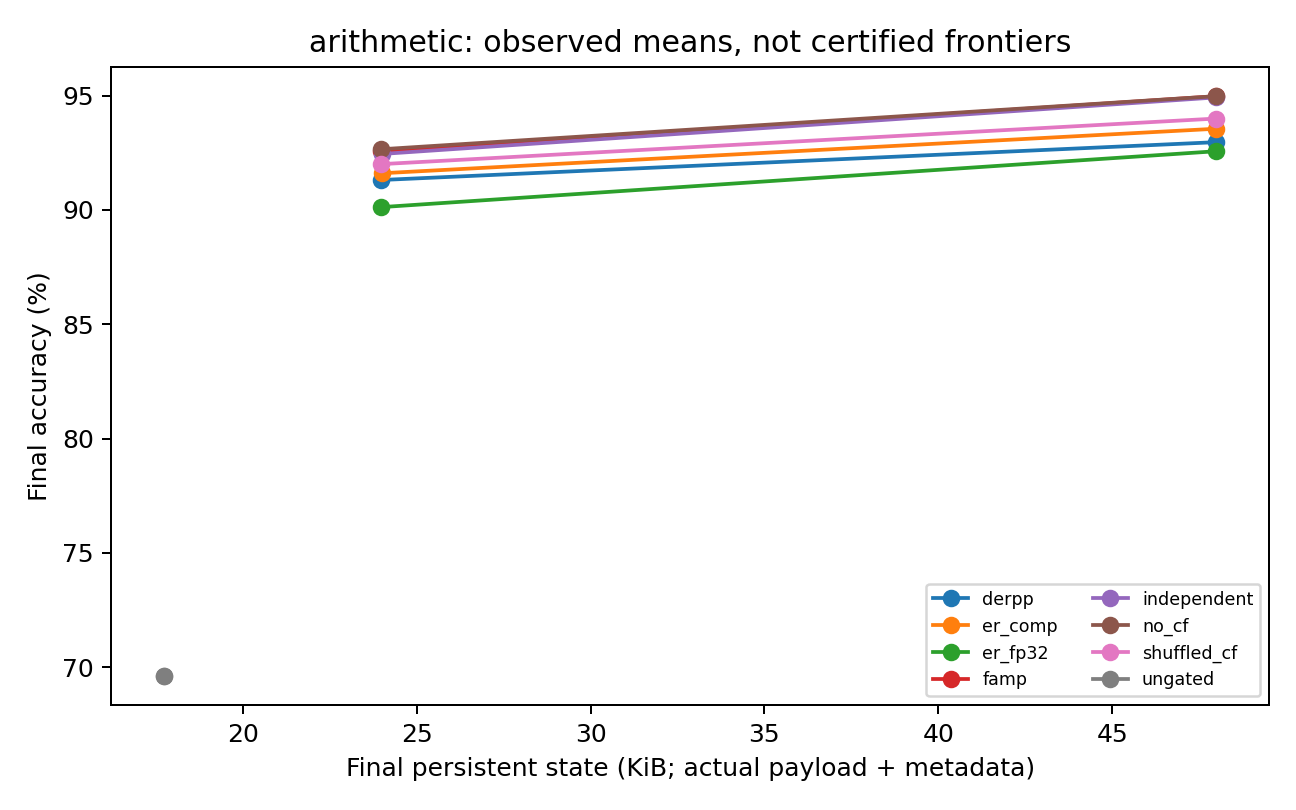

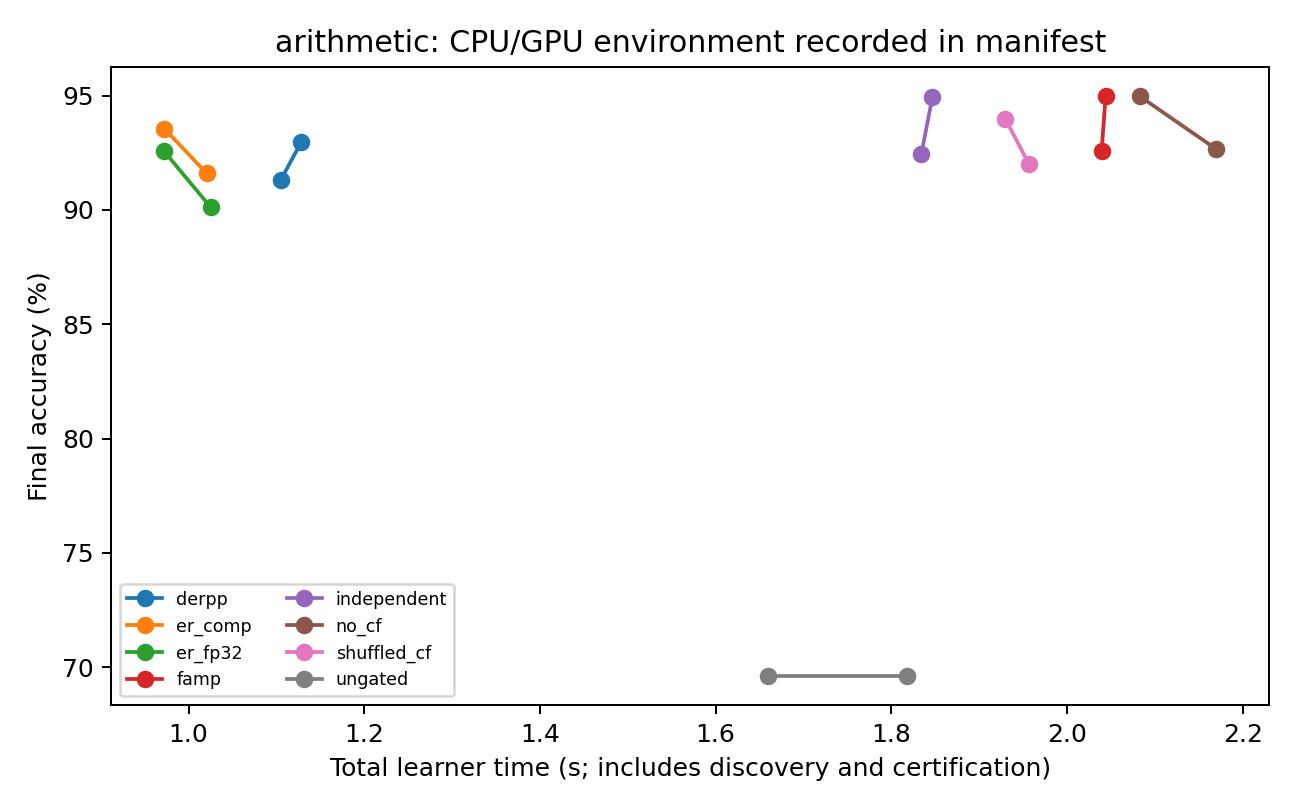

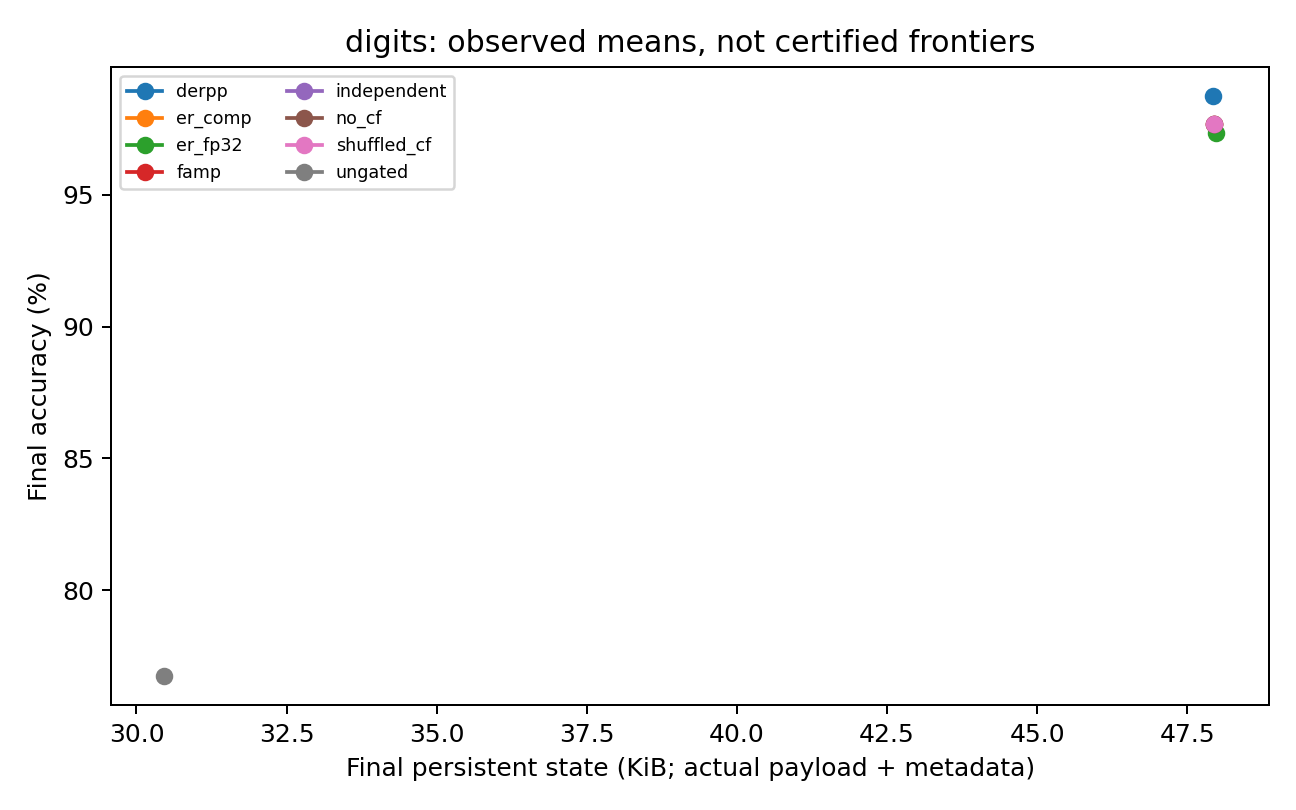

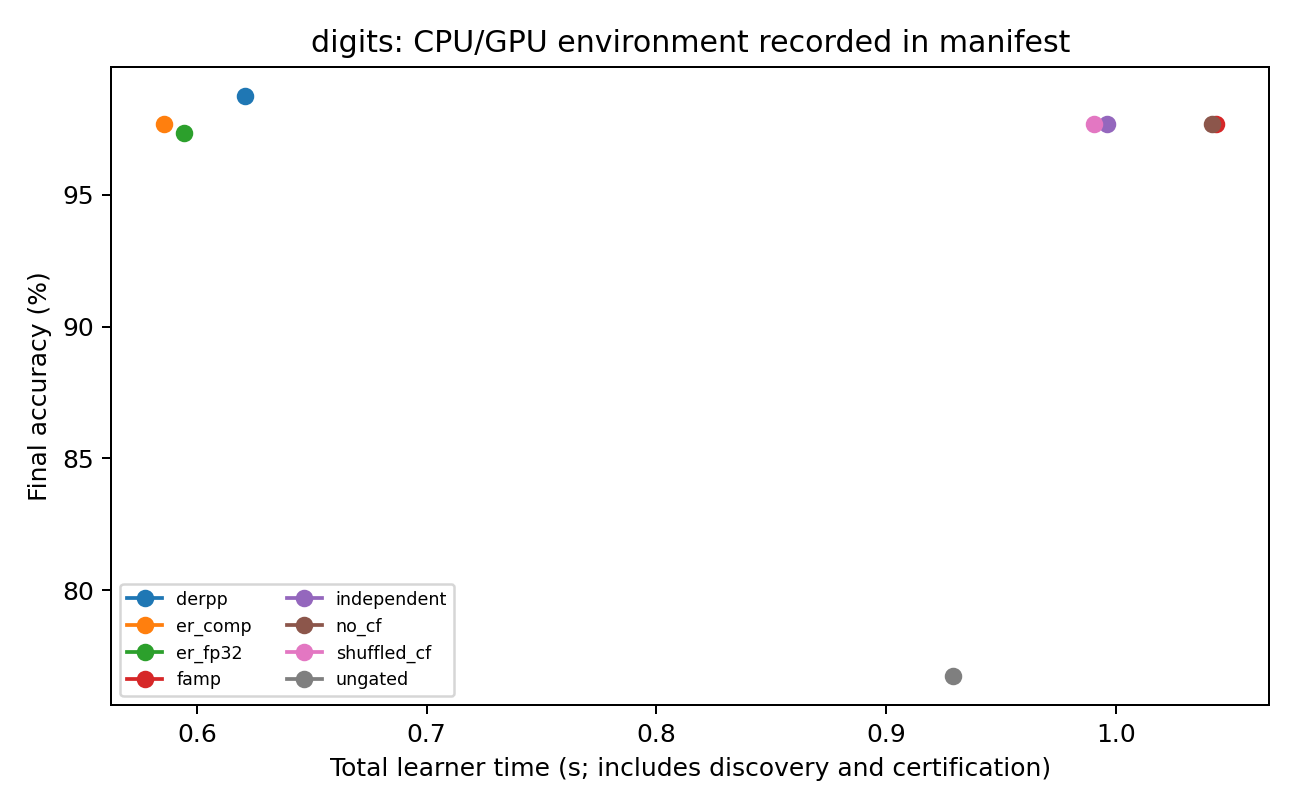

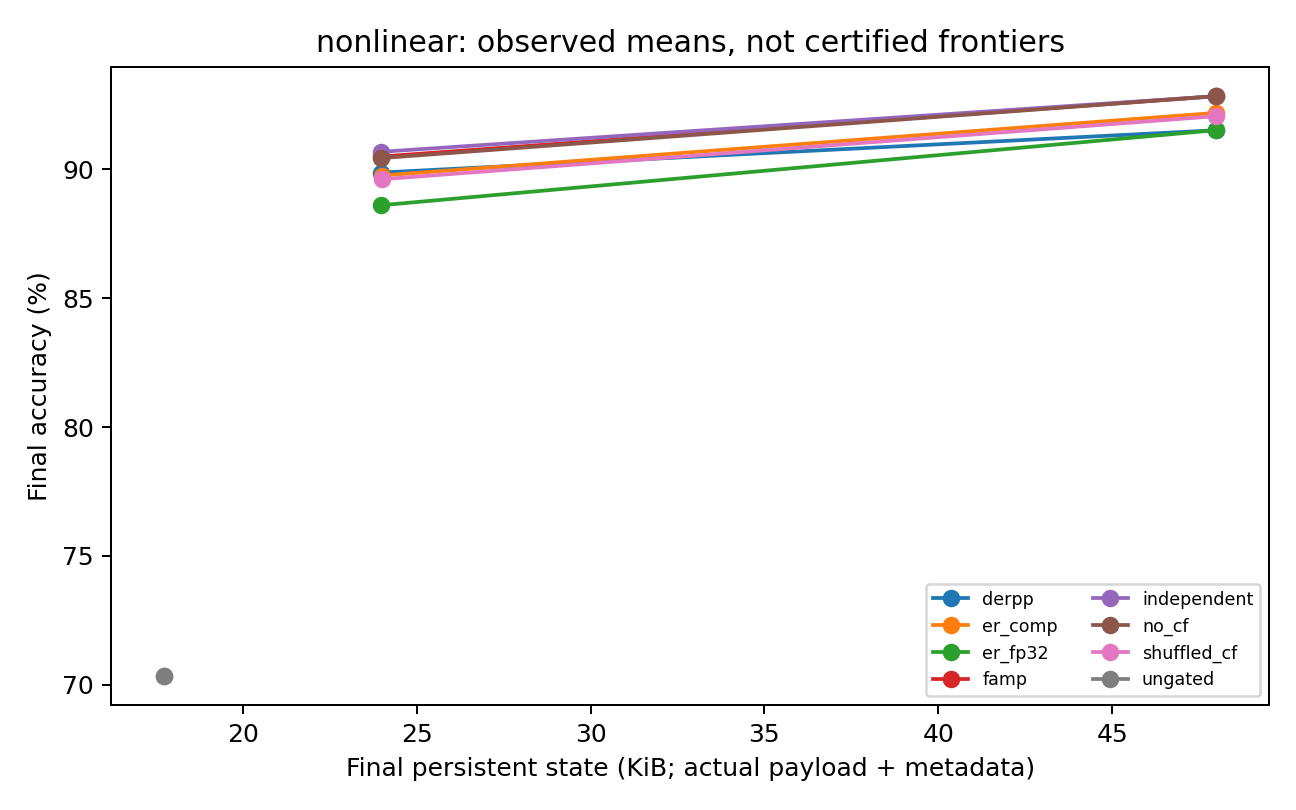

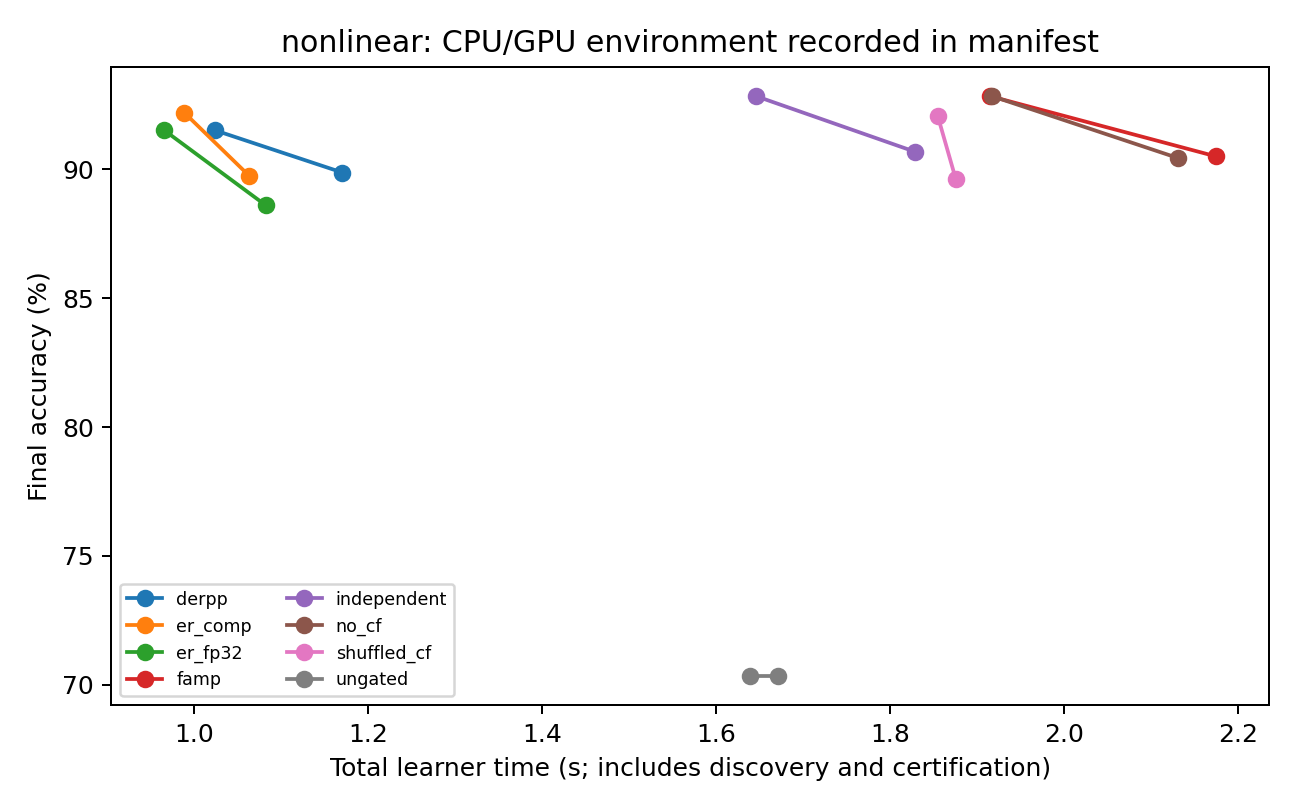

In [15]:
for figure in RESULT["figures"]:
    display(Image(filename=str(ROOT/"figures"/figure),width=760))

## 17. Actual operational example
The example exposes raw inputs, unit IDs, task heads, acceptance statistics, resulting logits, and the full byte ledger. It illustrates the object that is stored and reused, not an inferred symbolic label.

In [16]:
EXAMPLE=A.worked_example(ROOT,CFG)
display(Markdown(EXAMPLE))

# Actual shared-unit worked example

The first FAMP reuse/compose event in the predeclared loop order is used; the case
is not selected for high accuracy. The input is the first test example by index.

Family: arithmetic; seed: 839; budget: 24576 bytes; task: 5.
Action: compose; committed physical unit IDs: [0, 1].

## Admission evidence (separate selection and acceptance sets)
```json
{
  "candidate_accuracy": 0.953125,
  "teacher_accuracy": 0.9140625,
  "harmful": 7,
  "n": 256,
  "harm_upper": 0.0649845751677964,
  "pooled_upper_diagnostic": 0.0649845751677964,
  "sampling": "iid",
  "response_rmse": 0.19561442284698752,
  "alpha": 0.005555555555555556
}
```
## What is executed at inference
Raw input = [0.9837999939918518, 1.0053000450134277, -0.04050000011920929, 0.7436000108718872, -0.8835999965667725, 0.8659999966621399, -0.5504999756813049, 0.9587000012397766]

Features from stored unit(s) = [0.8555999994277954, 0.6111999750137329, 0.0, 1.0815000534057617, 0.0, 0.9376999735832214, 0.7491000294685364, 0.8894000053405762, 0.7989000082015991, 1.0296000242233276, 1.1384999752044678, 0.0, 0.44940000772476196, 0.8600000143051147, 0.6747000217437744, 0.745199978351593]

Two-class logits = [-0.052000001072883606, -0.024399999529123306]; true class = 0.

After deleting the contribution of physical unit 0, logits = [0.07689999788999557, -0.026900000870227814].

Physical unit 0 is referenced by task IDs [0, 5]. Only one parameter copy
is retained. Task heads, certificate witnesses and routing IDs are additional
objects whose costs are charged. This is executable sharing, not proof that the
unit is a uniquely named arithmetic concept. These numbers are observer-only and
never selected or trained the stored unit.

## Final byte ledger
```json
{
  "base": 13256,
  "units": 2240,
  "heads": 280,
  "witnesses": 312,
  "metadata": 998,
  "replay": 7476,
  "persistent": 24562
}
```


## 18. Round-trip verification
Reconstruct every final model from its saved state. Compare its predictions with the saved accuracy matrix and recalculate persistent bytes. There is no reliance on an in-memory model surviving notebook execution.

In [17]:
RECEIPT=A.postflight(ROOT,CFG)
print("Reconstructed checkpoints:",RECEIPT["checkpoints"])
print("Maximum accuracy discrepancy:",RECEIPT["max_accuracy_error"])
print("Post-run assertions:",len(RECEIPT["checks"]))

Reconstructed checkpoints: 120
Maximum accuracy discrepancy: 1.1102230246251565e-16
Post-run assertions: 126


## 19. Research insights generated from this execution
The method has to earn each claim separately: executable sharing, safe admission, resource reduction, and competitive generalization. The report retains negative and inconclusive comparisons. Pilot numbers stay out of the empty paper tables.

In [18]:
display(Markdown(RESULT["report"]))

# FAMP: executable shared functional memory — pilot evidence

Protocol `famp-executable-memory-1.1.1`; 120 sequential runs; seeds (811, 823, 839); device cpu; 32 passing startup checks.

**Status:** executed development evidence, not publication confirmation. This is a new learner that stores immutable executable units and task heads. It does not store a parameter-gradient basis. The main paper intentionally retains blank result tables.

## Scope and fairness

Task identity is supplied at inference. Synthetic task rules are known ONLY to the data generator and observer. No numerical primitive labels or counterfactual labels train the learner. Counterfactual validation means agreement with the current learned fallback teacher under declared perturbations; it is not a proof of semantic abstraction. Digits is binary task-incremental 8×8 recognition, not ten-class class-incremental learning. CIFAR is an optional separately labeled ten-task, ten-way task-incremental runner.

All methods train the same fallback backbone with current data and retained replay. FAMP then pays for candidate discovery, head fitting, selection and certification. Committed covered tasks no longer keep episodic replay except bounded witnesses. Independent uses the same new-unit builder and gate but cannot share old units. No-CF removes only the response gate. Ungated bypasses quality checks, not the byte limit. No result is automatically better simply because fewer examples are stored.

## Measured outcomes

### arithmetic

|                        |   accuracy |   acquisition |   forgetting |   final_persistent |   peak_persistent |   train_seconds |   units |   covered_tasks |   reuse_commits |
|:-----------------------|-----------:|--------------:|-------------:|-------------------:|------------------:|----------------:|--------:|----------------:|----------------:|
| (24576, 'derpp')       |     0.9131 |        0.8931 |       0.0151 |            24555   |           24555   |          1.1049 |  0      |          0      |          0      |
| (24576, 'er_comp')     |     0.916  |        0.9112 |       0.0298 |            24566   |           24566   |          1.0206 |  0      |          0      |          0      |
| (24576, 'er_fp32')     |     0.9012 |        0.9159 |       0.0409 |            24554   |           24554   |          1.0251 |  0      |          0      |          0      |
| (24576, 'famp')        |     0.9256 |        0.9176 |       0.0266 |            24562   |           24571.7 |          2.0392 |  3      |          3.3333 |          0.3333 |
| (24576, 'independent') |     0.9245 |        0.9196 |       0.0297 |            24566   |           24573.3 |          1.8341 |  3      |          3      |          0      |
| (24576, 'no_cf')       |     0.9266 |        0.9203 |       0.0281 |            24562.7 |           24570   |          2.1699 |  2.6667 |          3.3333 |          0.6667 |
| (24576, 'shuffled_cf') |     0.92   |        0.913  |       0.0276 |            24564.7 |           24564.7 |          1.9567 |  0.6667 |          0.6667 |          0      |
| (24576, 'ungated')     |     0.6961 |        0.6961 |       0      |            18161.7 |           18161.7 |          1.8174 |  1      |          9      |          8      |
| (49152, 'derpp')       |     0.9296 |        0.8935 |       0.006  |            49131   |           49131   |          1.1283 |  0      |          0      |          0      |
| (49152, 'er_comp')     |     0.9355 |        0.9171 |       0.0154 |            49150   |           49150   |          0.9726 |  0      |          0      |          0      |
| (49152, 'er_fp32')     |     0.9257 |        0.9151 |       0.0249 |            49150   |           49150   |          0.9721 |  0      |          0      |          0      |
| (49152, 'famp')        |     0.9497 |        0.9211 |       0.0079 |            49138   |           49144   |          2.0439 |  2.6667 |          3.3333 |          0.6667 |
| (49152, 'independent') |     0.9492 |        0.9222 |       0.0091 |            49145   |           49151   |          1.8466 |  3.3333 |          3.3333 |          0      |
| (49152, 'no_cf')       |     0.9497 |        0.9211 |       0.0079 |            49139   |           49145   |          2.0826 |  2.6667 |          3.3333 |          0.6667 |
| (49152, 'shuffled_cf') |     0.94   |        0.914  |       0.0138 |            49129.7 |           49129.7 |          1.9295 |  0.6667 |          0.6667 |          0      |
| (49152, 'ungated')     |     0.6961 |        0.6961 |       0      |            18161.7 |           18161.7 |          1.6592 |  1      |          9      |          8      |

B=24576: FAMP minus er_comp: {'mean': 0.9548611111111124, 'lo': -0.6252508676417304, 'hi': 2.5349730898639553, 'n': 3} percentage points (paired across seeds).

B=24576: FAMP minus derpp: {'mean': 1.2490354938271553, 'lo': 0.39678187818738264, 'hi': 2.101289109466928, 'n': 3} percentage points (paired across seeds).

B=24576: FAMP minus independent: {'mean': 0.11091820987653896, 'lo': -0.1989405244600107, 'hi': 0.4207769442130886, 'n': 3} percentage points (paired across seeds).

B=24576: FAMP minus no_cf: {'mean': -0.09645061728394595, 'lo': -0.5114441290267366, 'hi': 0.31854289445884476, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus er_comp: {'mean': 1.422646604938275, 'lo': 0.041740494897766434, 'hi': 2.8035527149787836, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus derpp: {'mean': 2.0109953703703685, 'lo': 1.1612714534412676, 'hi': 2.860719287299469, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus independent: {'mean': 0.05304783950618175, 'lo': -0.65700351236473, 'hi': 0.7630991913770935, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus no_cf: {'mean': 0.0, 'lo': 0.0, 'hi': 0.0, 'n': 3} percentage points (paired across seeds).

FAMP mean committed reuse count: 0.50; mean allocated units: 2.83. Decision counts (dependent task events): `{'accepted': 20, 'teacher_competent;bounded_harm': 4, 'selection_accuracy': 16, 'bounded_harm;response': 8, 'teacher_competent': 2, 'response': 1, 'bounded_harm': 3}`.

### digits

|                        |   accuracy |   acquisition |   forgetting |   final_persistent |   peak_persistent |   train_seconds |   units |   covered_tasks |   reuse_commits |
|:-----------------------|-----------:|--------------:|-------------:|-------------------:|------------------:|----------------:|--------:|----------------:|----------------:|
| (49152, 'derpp')       |     0.9874 |        0.9866 |       0.0046 |              49082 |             49082 |          0.6209 |       0 |               0 |               0 |
| (49152, 'er_comp')     |     0.977  |        0.9865 |       0.0156 |              49093 |             49093 |          0.5856 |       0 |               0 |               0 |
| (49152, 'er_fp32')     |     0.9733 |        0.9857 |       0.0184 |              49135 |             49135 |          0.5943 |       0 |               0 |               0 |
| (49152, 'famp')        |     0.977  |        0.9865 |       0.0156 |              49090 |             49090 |          1.0438 |       0 |               0 |               0 |
| (49152, 'independent') |     0.977  |        0.9865 |       0.0156 |              49097 |             49097 |          0.9963 |       0 |               0 |               0 |
| (49152, 'no_cf')       |     0.977  |        0.9865 |       0.0156 |              49091 |             49091 |          1.0418 |       0 |               0 |               0 |
| (49152, 'shuffled_cf') |     0.977  |        0.9865 |       0.0156 |              49097 |             49097 |          0.9905 |       0 |               0 |               0 |
| (49152, 'ungated')     |     0.7674 |        0.7674 |       0      |              31190 |             31190 |          0.9291 |       1 |               5 |               4 |

B=49152: FAMP minus er_comp: {'mean': 0.0, 'lo': 0.0, 'hi': 0.0, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus derpp: {'mean': -1.0388870388870413, 'lo': -1.8978029087271904, 'hi': -0.17997116904689203, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus independent: {'mean': 0.0, 'lo': 0.0, 'hi': 0.0, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus no_cf: {'mean': 0.0, 'lo': 0.0, 'hi': 0.0, 'n': 3} percentage points (paired across seeds).

FAMP mean committed reuse count: 0.00; mean allocated units: 0.00. Decision counts (dependent task events): `{'bounded_harm': 15}`.

### nonlinear

|                        |   accuracy |   acquisition |   forgetting |   final_persistent |   peak_persistent |   train_seconds |   units |   covered_tasks |   reuse_commits |
|:-----------------------|-----------:|--------------:|-------------:|-------------------:|------------------:|----------------:|--------:|----------------:|----------------:|
| (24576, 'derpp')       |     0.8987 |        0.8806 |       0.0148 |            24555   |           24555   |          1.1705 |  0      |          0      |               0 |
| (24576, 'er_comp')     |     0.8976 |        0.8946 |       0.029  |            24566   |           24566   |          1.063  |  0      |          0      |               0 |
| (24576, 'er_fp32')     |     0.886  |        0.8904 |       0.0315 |            24554   |           24554   |          1.0823 |  0      |          0      |               0 |
| (24576, 'famp')        |     0.9049 |        0.8927 |       0.024  |            24559.3 |           24571.7 |          2.1756 |  2      |          2      |               0 |
| (24576, 'independent') |     0.9068 |        0.8924 |       0.022  |            24556   |           24569   |          1.8291 |  2      |          2      |               0 |
| (24576, 'no_cf')       |     0.9043 |        0.893  |       0.0247 |            24551   |           24570   |          2.1317 |  2      |          2      |               0 |
| (24576, 'shuffled_cf') |     0.8961 |        0.8934 |       0.0303 |            24567.7 |           24571.7 |          1.8759 |  1      |          1      |               0 |
| (24576, 'ungated')     |     0.7034 |        0.7034 |       0      |            18158.7 |           18158.7 |          1.6717 |  1      |          9      |               8 |
| (49152, 'derpp')       |     0.9151 |        0.8815 |       0.0081 |            49131   |           49131   |          1.0239 |  0      |          0      |               0 |
| (49152, 'er_comp')     |     0.9219 |        0.8937 |       0.0086 |            49150   |           49150   |          0.9889 |  0      |          0      |               0 |
| (49152, 'er_fp32')     |     0.9152 |        0.8961 |       0.0149 |            49150   |           49150   |          0.9654 |  0      |          0      |               0 |
| (49152, 'famp')        |     0.9283 |        0.8948 |       0.0087 |            49132.7 |           49132.7 |          1.9155 |  2      |          2      |               0 |
| (49152, 'independent') |     0.9283 |        0.8948 |       0.0087 |            49139.7 |           49139.7 |          1.6463 |  2      |          2      |               0 |
| (49152, 'no_cf')       |     0.9283 |        0.8948 |       0.0087 |            49133.7 |           49133.7 |          1.9177 |  2      |          2      |               0 |
| (49152, 'shuffled_cf') |     0.9206 |        0.8952 |       0.0132 |            49129.3 |           49129.3 |          1.8552 |  0.6667 |          0.6667 |               0 |
| (49152, 'ungated')     |     0.7034 |        0.7034 |       0      |            18158.7 |           18158.7 |          1.6396 |  1      |          9      |               8 |

B=24576: FAMP minus er_comp: {'mean': 0.7378472222222173, 'lo': -0.11793540899238353, 'hi': 1.593629853436818, 'n': 3} percentage points (paired across seeds).

B=24576: FAMP minus derpp: {'mean': 0.6221064814814806, 'lo': -1.5936441066007632, 'hi': 2.837857069563724, 'n': 3} percentage points (paired across seeds).

B=24576: FAMP minus independent: {'mean': -0.18325617283951137, 'lo': -1.399017187152513, 'hi': 1.03250484147349, 'n': 3} percentage points (paired across seeds).

B=24576: FAMP minus no_cf: {'mean': 0.06269290123456228, 'lo': -0.20705288139824057, 'hi': 0.33243868386736514, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus er_comp: {'mean': 0.6462191358024801, 'lo': 0.3122847102401612, 'hi': 0.9801535613647991, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus derpp: {'mean': 1.321373456790124, 'lo': 0.42336546893713767, 'hi': 2.2193814446431106, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus independent: {'mean': 0.0, 'lo': 0.0, 'hi': 0.0, 'n': 3} percentage points (paired across seeds).

B=49152: FAMP minus no_cf: {'mean': 0.0, 'lo': 0.0, 'hi': 0.0, 'n': 3} percentage points (paired across seeds).

FAMP mean committed reuse count: 0.00; mean allocated units: 2.00. Decision counts (dependent task events): `{'accepted': 12, 'teacher_competent;bounded_harm': 6, 'bounded_harm;response': 13, 'bounded_harm': 14, 'selection_accuracy': 9}`.

## Shared executable use
| family     |     drop |   dependents |
|:-----------|---------:|-------------:|
| arithmetic | 0.347765 |            2 |
Ablation deletes the unit input to its actual task heads. This verifies dependence on a shared executable object, not a named human arithmetic concept; readout failure from deletion alone is not formal causal abstraction.

## What is safe to conclude

The finite unit/head input-output paths are immutable. All bounded stored-witness checks preserve their logits within 1e-6 across later fallback training. This is a designed isolation guarantee, not discovered spontaneous neural stability. Uncovered tasks can still forget in the replay fallback.

Strict accounting assertions pass at every commit: fallback model, shared weights counted once, every task head, bounded certificate payload, canonical metadata and retained replay all fit the selected byte budget. Current-task datasets, training gradients, Adam state and candidate copies are workspace, not persistent state; measured CUDA peak is separate. CPU process peak is not measured. Checkpoint container overhead is reported separately from payload bytes.

A one-sided binomial bound (with per-class union bounds for stratified image splits) certifies only harmful disagreements with a learned teacher on independent acceptance examples. It cannot ensure ground-truth quality outside that distribution, and the response tolerance is an exploratory consistency threshold rather than a semantic theorem. Alpha spending is across task commits; selection and acceptance examples are disjoint.

## Paper-filling decision

No confirmatory number is inserted into the manuscript. Evaluate the exact-byte accuracy/time trade-off, sharing ablation, certificate false acceptance, stream length and natural-image performance under the frozen protocol before using words such as superior, memory-efficient, or state of the art. The pilot is an implementation and mechanism test, not an MLSys-scale result.

## Remaining work recorded, not claimed completed

Full CIFAR-100 task-incremental runs, class-incremental applicability, multiple hardware measurements, a calibrated fixed-accuracy minimum-byte comparison, and matched public modular-CL/latent-replay reproduction are not established by this pilot. Expanded profiles are prospective experiments. This artifact never substitutes synthetic values for an unavailable dataset.

## Artifacts

`runs/*/events.json` holds every proposal/decision; `ledger.csv` records complete commit-state accounting; `reuse_ablation.csv` links physical unit IDs to dependent tasks. `all_runs.csv`, `events.json`, configuration, environment and SHA-256 manifest allow independent audit.

## 20. Confirmation and system-scale measurements
The optional profiles run the same algorithm. Their existence is not evidence that the corresponding measurements were performed. CIFAR is ten-way **task-aware** classification with a task-specific route; it must not be reported as task-agnostic 100-way class-incremental learning. The small calibration set in Digits is intentionally not recycled as training data to make the acceptance rule pass.

Before populating the paper, freeze model and admission settings using separate development sequences; run five new seeds and multiple task orders; profile complete CPU/GPU work, packed state and serialization; and reproduce the public modular/latent-replay comparators listed in the appendix. The tiny convolutional runner is implemented, but a competitive ResNet/public-baseline integration and hardware evaluation remain required for venue-level claims.

In [19]:
RUN_LARGE=False
if RUN_LARGE:
    # Explicitly opt in; downloads may fail and no substitute data are generated.
    c=E.config("cifar",output="famp_cifar_results",seeds=(1009,1013,1019,1021,1031),orders=(0,1,2))
    LARGE=E.run(c)
else:
    print("Large-benchmark and multi-device confirmation: NOT EXECUTED in this notebook run.")

Large-benchmark and multi-device confirmation: NOT EXECUTED in this notebook run.


## 21. Export the audit trail
The archive contains the exact engine, helpers, configuration, environment, checkpoint dictionaries, measured tables, figures, examples, and receipts. A manifest hashes every file. Output archives are not an online replay store; observer artifacts are deliberately separate from the learner's budget.

In [20]:
import shutil, hashlib
shutil.copy2("famp_engine.py",ROOT/"famp_engine.py")
shutil.copy2("artifact_tools.py",ROOT/"artifact_tools.py")
manifest={"protocol":E.PROTOCOL,"environment":E.env(),"files":{}}
for p in sorted(ROOT.rglob("*")):
    if p.is_file() and p.name!="manifest.json":
        manifest["files"][str(p.relative_to(ROOT))]={"bytes":p.stat().st_size,"sha256":hashlib.sha256(p.read_bytes()).hexdigest()}
(ROOT/"manifest.json").write_text(json.dumps(manifest,indent=2))
ARCHIVE=shutil.make_archive(str(ROOT.resolve())+"_results","zip",root_dir=ROOT)
print("Archive:",ARCHIVE)
print("Insights:",(ROOT/"insights.md").resolve())

Archive: /mnt/data/famp_submission/results/notebook_execution/famp_executed_results_results.zip
Insights: /mnt/data/famp_submission/results/notebook_execution/famp_executed_results/insights.md


## 22. Sources and manuscript linkage
The full checked bibliography and reference-audit ledger accompany the manuscript. Key sources: Veniat, Denoyer & Ranzato (ICLR 2021), *Efficient Continual Learning with Modular Networks and Task-Driven Priors*; Mendez & Eaton (ICLR 2021), *Lifelong Learning of Compositional Structures*; Buzzega et al. (NeurIPS 2020), *Dark Experience for General Continual Learning*; Hayes et al. (ECCV 2020), *REMIND*; Geiger et al. (ICML 2022 and CLeaR 2024), causal/interchange alignment; Clopper & Pearson (1934), binomial bounds; Seo, Koh & Choi (arXiv 2410.15143), complete resource budgets.

**Attribution:** module reuse, distillation, risk bounds, and byte accounting individually have prior art. The proposed contribution is the particular bounded replacement policy and its measured systems trade-off, which remains a hypothesis until the required comparisons succeed. No inherited formal abstraction or state-of-the-art claim is made.